# ASD Classification from Eye-Tracking Data

Binary classification of **Autism Spectrum Disorder (ASD, label 1)** vs **Typically Developing (TD, label 0)** children using the eye-tracking dataset of Cilia et al. (2022).

Two approaches are compared:

1. **Image-based** – pretrained CNNs / vision transformers (ResNet50, DenseNet121, ViT-B/16, Swin-T) fine-tuned on scanpath images (`Images/TSImages`, `Images/TCImages`).
2. **Tabular** – per-participant features aggregated from the raw eye-tracking recordings (fixation/saccade proportions, pupil size, point of regard statistics), classified with a neural network and classical ML models.

> **Note:** images are split at image level, so images from the same participant can appear in both train and test sets. Tabular results use a very small test set (~12 participants). Treat the numbers as preliminary – see README.


## Setup

In [ ]:
from pathlib import Path

# Works on Google Colab (Drive) and locally (dataset folders next to this notebook; see README).
try:
    from google.colab import drive
    drive.mount('/content/drive')
    DATA_DIR = Path('/content/drive/MyDrive/ASD Level')
except ImportError:
    DATA_DIR = Path('.')

for sub in ['Images/TSImages', 'Images/TCImages', 'Eye-Tracking Dataset/Eye-tracking Output']:
    assert (DATA_DIR / sub).exists(), f"Missing {DATA_DIR / sub} - see README for dataset setup"


## 1. Image-based Models

### Dataset

In [ ]:
import os
from PIL import Image
import torch
from torchvision import transforms
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split

# Define image transformation (resize, normalize, etc.)
transform = transforms.Compose([
    transforms.Resize((224, 224)),  # Resize images to 224x224
    transforms.ToTensor(),  # Convert image to tensor
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])  # Normalize using ImageNet values
])

# Custom Dataset class to load images and assign labels
class CustomImageDataset(Dataset):
    def __init__(self, image_dir, label, transform=None):
        self.image_dir = image_dir
        self.transform = transform
        self.images = os.listdir(image_dir)
        self.label = label

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        img_path = os.path.join(self.image_dir, self.images[idx])
        image = Image.open(img_path).convert("RGB")
        if self.transform:
            image = self.transform(image)
        return image, self.label

# Load images from both directories
img_dir_1 = str(DATA_DIR / 'Images/TSImages')
img_dir_2 = str(DATA_DIR / 'Images/TCImages')

# Create dataset instances for both classes
ts_dataset = CustomImageDataset(image_dir=img_dir_1, label=1, transform=transform)
tc_dataset = CustomImageDataset(image_dir=img_dir_2, label=0, transform=transform)

# Combine both datasets
full_dataset = ts_dataset + tc_dataset

# Get image indices for train-test split
indices = list(range(len(full_dataset)))
train_indices, test_indices = train_test_split(indices, test_size=0.2, random_state=42, stratify=[label for _, label in full_dataset])

# Create DataLoaders for training and testing
train_loader = DataLoader(full_dataset, batch_size=32, sampler=torch.utils.data.SubsetRandomSampler(train_indices))
test_loader = DataLoader(full_dataset, batch_size=32, sampler=torch.utils.data.SubsetRandomSampler(test_indices))


In [ ]:
from collections import Counter

# Create a function to count the labels in a subset
def count_labels(dataset, indices):
    labels = [dataset[idx][1] for idx in indices]  # Get the label (class) from the dataset
    return Counter(labels)  # Count occurrences of each label

# Count labels in the training set
train_label_counts = count_labels(full_dataset, train_indices)
print(f"Training set label distribution: {train_label_counts}")

# Count labels in the test set
test_label_counts = count_labels(full_dataset, test_indices)
print(f"Test set label distribution: {test_label_counts}")


Training set label distribution: Counter({0: 262, 1: 175})
Test set label distribution: Counter({0: 66, 1: 44})


### ResNet50

In [ ]:

import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import models

# Load the pretrained ResNet50 model
resnet_model = models.resnet50(weights="DEFAULT")

# Freeze the early layers (optional)
for param in resnet_model.parameters():
    param.requires_grad = False

# Replace the final fully connected layer to match the number of classes in your task
num_ftrs = resnet_model.fc.in_features
resnet_model.fc = nn.Linear(num_ftrs, 2)  # Assuming 2 classes (label 0 and label 1)

# Move the model to GPU if available
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
resnet_model = resnet_model.to(device)

# Define the loss function and optimizer
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(resnet_model.fc.parameters(), lr=0.001)

# Training the model
num_epochs = 100
for epoch in range(num_epochs):
    resnet_model.train()
    running_loss = 0.0
    for inputs, labels in train_loader:
        inputs, labels = inputs.to(device), labels.to(device)

        # Zero the parameter gradients
        optimizer.zero_grad()

        # Forward pass
        outputs = resnet_model(inputs)
        loss = criterion(outputs, labels)

        # Backward pass and optimize
        loss.backward()
        optimizer.step()

        # Accumulate loss
        running_loss += loss.item()

    print(f"Epoch [{epoch+1}/{num_epochs}], Loss: {running_loss/len(train_loader):.4f}")

print("Finished Training")


Epoch [1/100], Loss: 0.2859
Epoch [2/100], Loss: 0.2908
Epoch [3/100], Loss: 0.2737
Epoch [4/100], Loss: 0.2431
Epoch [5/100], Loss: 0.2748
Epoch [6/100], Loss: 0.2417
Epoch [7/100], Loss: 0.2569
Epoch [8/100], Loss: 0.2733
Epoch [9/100], Loss: 0.2494
Epoch [10/100], Loss: 0.2293
Epoch [11/100], Loss: 0.2776
Epoch [12/100], Loss: 0.2440
Epoch [13/100], Loss: 0.2226
Epoch [14/100], Loss: 0.2851
Epoch [15/100], Loss: 0.2990
Epoch [16/100], Loss: 0.2422
Epoch [17/100], Loss: 0.2168
Epoch [18/100], Loss: 0.2163
Epoch [19/100], Loss: 0.2203
Epoch [20/100], Loss: 0.2178
Epoch [21/100], Loss: 0.2805
Epoch [22/100], Loss: 0.2574
Epoch [23/100], Loss: 0.3064
Epoch [24/100], Loss: 0.2974
Epoch [25/100], Loss: 0.2761
Epoch [26/100], Loss: 0.2178
Epoch [27/100], Loss: 0.2584
Epoch [28/100], Loss: 0.2196
Epoch [29/100], Loss: 0.2498
Epoch [30/100], Loss: 0.2419
Epoch [31/100], Loss: 0.2314
Epoch [32/100], Loss: 0.2161
Epoch [33/100], Loss: 0.1990
Epoch [34/100], Loss: 0.2458
Epoch [35/100], Loss: 0

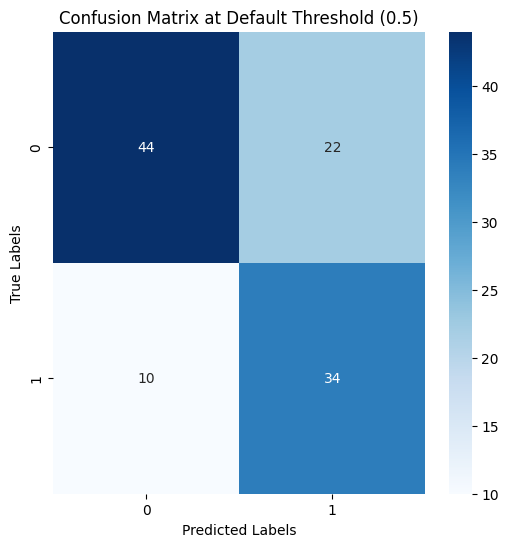

Test Accuracy: 0.7091
Test Precision: 0.6071
Test Recall: 0.7727
Test F1 Score: 0.6800


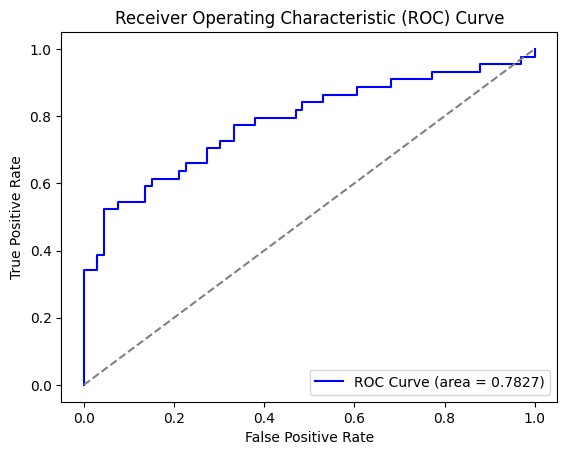

Best Threshold: 0.8749


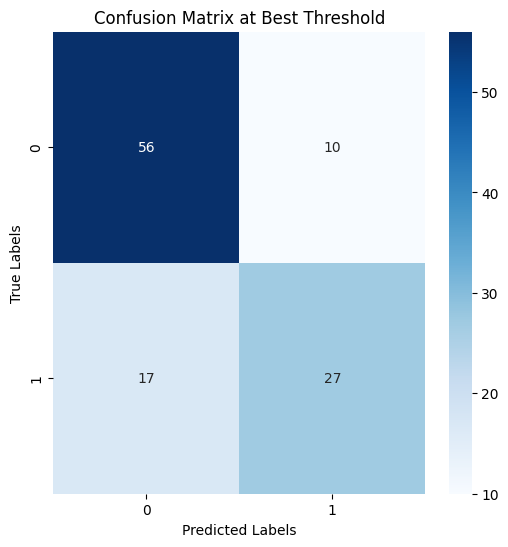

Best Threshold Accuracy: 0.7545
Best Threshold Precision: 0.7297
Best Threshold Recall: 0.6136
Best Threshold F1 Score: 0.6667


In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_curve, roc_auc_score, confusion_matrix
import numpy as np
import seaborn as sns

# Evaluate on the test set
resnet_model.eval()  # Set model to evaluation mode
all_labels = []
all_preds = []
all_probs = []  # To store probabilities for ROC curve

with torch.no_grad():
    for inputs, labels in test_loader:
        inputs, labels = inputs.to(device), labels.to(device)

        # Forward pass
        outputs = resnet_model(inputs)

        # Get probabilities
        probs = torch.softmax(outputs, dim=1)[:, 1]  # Get probabilities for class 1
        all_probs.extend(probs.cpu().numpy())

        # Get predictions (Default threshold 0.5)
        _, preds = torch.max(outputs, 1)

        # Store labels and predictions
        all_labels.extend(labels.cpu().numpy())
        all_preds.extend(preds.cpu().numpy())

# Confusion Matrix at Default Threshold (0.5)
conf_matrix_default = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(6, 6))
sns.heatmap(conf_matrix_default, annot=True, fmt="d", cmap="Blues", xticklabels=[0, 1], yticklabels=[0, 1])
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix at Default Threshold (0.5)')
plt.show()

# Calculate metrics at default threshold (0.5)
accuracy = accuracy_score(all_labels, all_preds)
precision = precision_score(all_labels, all_preds)
recall = recall_score(all_labels, all_preds)
f1 = f1_score(all_labels, all_preds)

print(f"Test Accuracy: {accuracy:.4f}")
print(f"Test Precision: {precision:.4f}")
print(f"Test Recall: {recall:.4f}")
print(f"Test F1 Score: {f1:.4f}")

# ROC Curve and AUC
fpr, tpr, thresholds = roc_curve(all_labels, all_probs)
roc_auc = roc_auc_score(all_labels, all_probs)

plt.figure()
plt.plot(fpr, tpr, color='blue', label=f'ROC Curve (area = {roc_auc:.4f})')
plt.plot([0, 1], [0, 1], color='gray', linestyle='--')  # Random guess line
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend(loc='lower right')
plt.show()

# Find the best threshold (closest to the top-left corner)
gmeans = np.sqrt(tpr * (1 - fpr))
ix = np.argmax(gmeans)
best_thresh = thresholds[ix]
print(f'Best Threshold: {best_thresh:.4f}')

# Apply best threshold to get new predictions
best_preds = (np.array(all_probs) >= best_thresh).astype(int)

# Confusion Matrix at Best Threshold
conf_matrix_best = confusion_matrix(all_labels, best_preds)
plt.figure(figsize=(6, 6))
sns.heatmap(conf_matrix_best, annot=True, fmt="d", cmap="Blues", xticklabels=[0, 1], yticklabels=[0, 1])
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix at Best Threshold')
plt.show()

# Calculate metrics based on best threshold
accuracy_best = accuracy_score(all_labels, best_preds)
precision_best = precision_score(all_labels, best_preds)
recall_best = recall_score(all_labels, best_preds)
f1_best = f1_score(all_labels, best_preds)

print(f"Best Threshold Accuracy: {accuracy_best:.4f}")
print(f"Best Threshold Precision: {precision_best:.4f}")
print(f"Best Threshold Recall: {recall_best:.4f}")
print(f"Best Threshold F1 Score: {f1_best:.4f}")


In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import models

# Load the pretrained ResNet50 model
resnet_model = models.resnet50(weights="DEFAULT")

# Freeze early layers (optional)
for param in resnet_model.parameters():
    param.requires_grad = False

# Replace final layer
num_ftrs = resnet_model.fc.in_features
resnet_model.fc = nn.Linear(num_ftrs, 2)

# Move to device
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
resnet_model = resnet_model.to(device)

# Loss and optimizer
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(resnet_model.fc.parameters(), lr=0.001)

# -----------------------------
# STORAGE LISTS WITH NEW NAMES
# -----------------------------
resnet_train_losses = []
resnet_val_losses = []
resnet_train_accuracies = []
resnet_val_accuracies = []

num_epochs = 100

for epoch in range(num_epochs):

    # --------------------------------
    # TRAINING
    # --------------------------------
    resnet_model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for inputs, labels in train_loader:
        inputs, labels = inputs.to(device), labels.to(device)

        optimizer.zero_grad()

        outputs = resnet_model(inputs)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item()

        # Accuracy
        _, predicted = torch.max(outputs, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    train_loss = running_loss / len(train_loader)
    train_acc = correct / total

    resnet_train_losses.append(train_loss)
    resnet_train_accuracies.append(train_acc)

    # --------------------------------
    # VALIDATION
    # --------------------------------
    resnet_model.eval()
    val_running_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for inputs, labels in test_loader:
            inputs, labels = inputs.to(device), labels.to(device)

            outputs = resnet_model(inputs)
            loss = criterion(outputs, labels)

            val_running_loss += loss.item()

            _, predicted = torch.max(outputs, 1)
            val_total += labels.size(0)
            val_correct += (predicted == labels).sum().item()

    val_loss = val_running_loss / len(test_loader)
    val_acc = val_correct / val_total

    resnet_val_losses.append(val_loss)
    resnet_val_accuracies.append(val_acc)

    print(f"Epoch {epoch+1}/{num_epochs} | "
          f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.4f} | "
          f"Val Loss: {val_loss:.4f} | Val Acc: {val_acc:.4f}")

print("Finished Training")


Epoch 1/100 | Train Loss: 0.6527 | Train Acc: 0.6430 | Val Loss: 0.6664 | Val Acc: 0.6273
Epoch 2/100 | Train Loss: 0.5654 | Train Acc: 0.7048 | Val Loss: 0.6220 | Val Acc: 0.6364
Epoch 3/100 | Train Loss: 0.5236 | Train Acc: 0.7368 | Val Loss: 0.6828 | Val Acc: 0.6000
Epoch 4/100 | Train Loss: 0.5558 | Train Acc: 0.7231 | Val Loss: 0.5505 | Val Acc: 0.7364
Epoch 5/100 | Train Loss: 0.5228 | Train Acc: 0.7254 | Val Loss: 0.4785 | Val Acc: 0.7818
Epoch 6/100 | Train Loss: 0.4897 | Train Acc: 0.7574 | Val Loss: 0.5088 | Val Acc: 0.7273
Epoch 7/100 | Train Loss: 0.4658 | Train Acc: 0.7780 | Val Loss: 0.5156 | Val Acc: 0.7455
Epoch 8/100 | Train Loss: 0.4515 | Train Acc: 0.8032 | Val Loss: 0.5143 | Val Acc: 0.7545
Epoch 9/100 | Train Loss: 0.4556 | Train Acc: 0.7712 | Val Loss: 0.5131 | Val Acc: 0.8000
Epoch 10/100 | Train Loss: 0.4307 | Train Acc: 0.8055 | Val Loss: 0.4780 | Val Acc: 0.7455
Epoch 11/100 | Train Loss: 0.4286 | Train Acc: 0.8146 | Val Loss: 0.4803 | Val Acc: 0.7818
Epoch 12

### DenseNet121

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import models

# Load the pretrained DenseNet121 model
densenet_model = models.densenet121(weights="DEFAULT")

# Freeze the early layers (optional)
for param in densenet_model.parameters():
    param.requires_grad = False

# Replace the final fully connected layer to match the number of classes in your task
num_ftrs = densenet_model.classifier.in_features
densenet_model.classifier = nn.Linear(num_ftrs, 2)  # Assuming 2 classes (label 0 and label 1)

# Move the model to GPU if available
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
densenet_model = densenet_model.to(device)

# Define the loss function and optimizer
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(densenet_model.classifier.parameters(), lr=0.001)

# Training the model
num_epochs = 100
for epoch in range(num_epochs):
    densenet_model.train()
    running_loss = 0.0
    for inputs, labels in train_loader:
        inputs, labels = inputs.to(device), labels.to(device)

        # Zero the parameter gradients
        optimizer.zero_grad()

        # Forward pass
        outputs = densenet_model(inputs)
        loss = criterion(outputs, labels)

        # Backward pass and optimize
        loss.backward()
        optimizer.step()

        # Accumulate loss
        running_loss += loss.item()

    print(f"Epoch [{epoch+1}/{num_epochs}], Loss: {running_loss/len(train_loader):.4f}")

print("Finished Training")


Epoch [1/100], Loss: 0.6573
Epoch [2/100], Loss: 0.5511
Epoch [3/100], Loss: 0.5096
Epoch [4/100], Loss: 0.4890
Epoch [5/100], Loss: 0.4730
Epoch [6/100], Loss: 0.4683
Epoch [7/100], Loss: 0.4882
Epoch [8/100], Loss: 0.4638
Epoch [9/100], Loss: 0.4377
Epoch [10/100], Loss: 0.4537
Epoch [11/100], Loss: 0.4242
Epoch [12/100], Loss: 0.4187
Epoch [13/100], Loss: 0.4022
Epoch [14/100], Loss: 0.4010
Epoch [15/100], Loss: 0.3900
Epoch [16/100], Loss: 0.4211
Epoch [17/100], Loss: 0.3970
Epoch [18/100], Loss: 0.3761
Epoch [19/100], Loss: 0.3954
Epoch [20/100], Loss: 0.3941
Epoch [21/100], Loss: 0.4147
Epoch [22/100], Loss: 0.3883
Epoch [23/100], Loss: 0.3688
Epoch [24/100], Loss: 0.3716
Epoch [25/100], Loss: 0.3427
Epoch [26/100], Loss: 0.3597
Epoch [27/100], Loss: 0.3593
Epoch [28/100], Loss: 0.3472
Epoch [29/100], Loss: 0.3565
Epoch [30/100], Loss: 0.3586
Epoch [31/100], Loss: 0.3510
Epoch [32/100], Loss: 0.3329
Epoch [33/100], Loss: 0.3563
Epoch [34/100], Loss: 0.3340
Epoch [35/100], Loss: 0

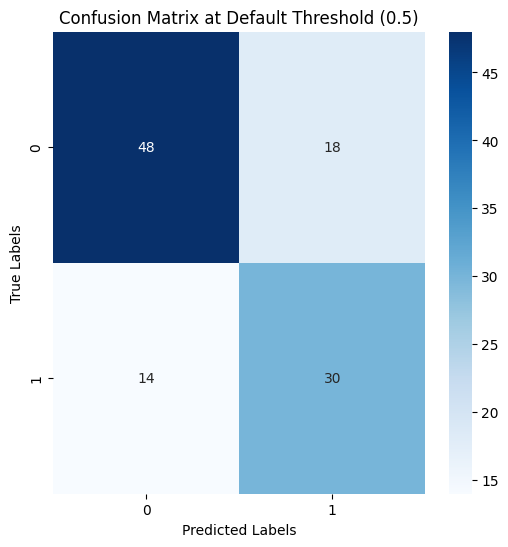

Test Accuracy: 0.7091
Test Precision: 0.6250
Test Recall: 0.6818
Test F1 Score: 0.6522


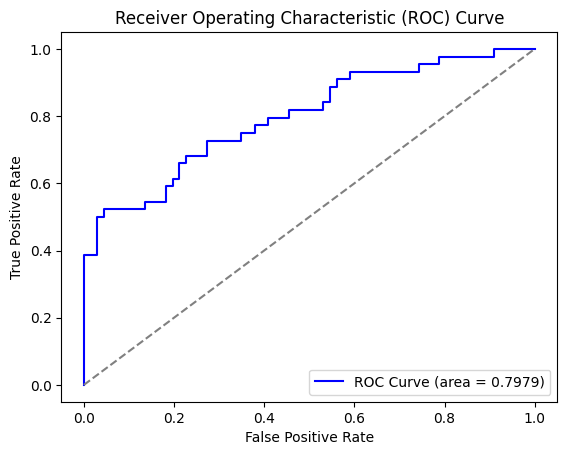

Best Threshold: 0.4679


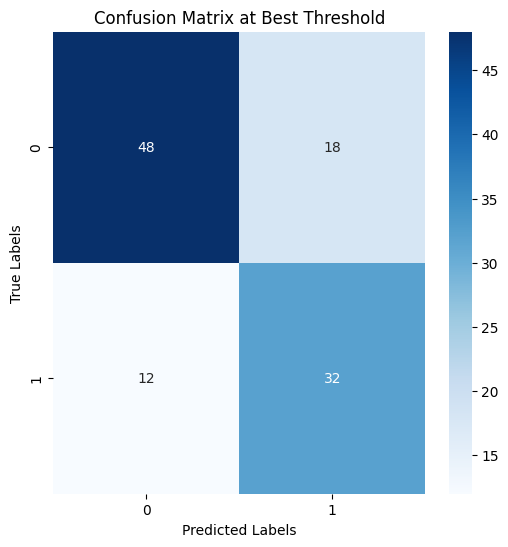

Best Threshold Accuracy: 0.7273
Best Threshold Precision: 0.6400
Best Threshold Recall: 0.7273
Best Threshold F1 Score: 0.6809


In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_curve, roc_auc_score, confusion_matrix
import numpy as np
import seaborn as sns

# Evaluate on the test set
densenet_model.eval()  # Set model to evaluation mode
all_labels = []
all_preds = []
all_probs = []  # To store probabilities for ROC curve

with torch.no_grad():
    for inputs, labels in test_loader:
        inputs, labels = inputs.to(device), labels.to(device)

        # Forward pass
        outputs = densenet_model(inputs)

        # Get probabilities
        probs = torch.softmax(outputs, dim=1)[:, 1]  # Get probabilities for class 1
        all_probs.extend(probs.cpu().numpy())

        # Get predictions (Default threshold 0.5)
        _, preds = torch.max(outputs, 1)

        # Store labels and predictions
        all_labels.extend(labels.cpu().numpy())
        all_preds.extend(preds.cpu().numpy())

# Confusion Matrix at Default Threshold (0.5)
conf_matrix_default = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(6, 6))
sns.heatmap(conf_matrix_default, annot=True, fmt="d", cmap="Blues", xticklabels=[0, 1], yticklabels=[0, 1])
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix at Default Threshold (0.5)')
plt.show()

# Calculate metrics at default threshold (0.5)
accuracy = accuracy_score(all_labels, all_preds)
precision = precision_score(all_labels, all_preds)
recall = recall_score(all_labels, all_preds)
f1 = f1_score(all_labels, all_preds)

print(f"Test Accuracy: {accuracy:.4f}")
print(f"Test Precision: {precision:.4f}")
print(f"Test Recall: {recall:.4f}")
print(f"Test F1 Score: {f1:.4f}")

# ROC Curve and AUC
fpr, tpr, thresholds = roc_curve(all_labels, all_probs)
roc_auc = roc_auc_score(all_labels, all_probs)

plt.figure()
plt.plot(fpr, tpr, color='blue', label=f'ROC Curve (area = {roc_auc:.4f})')
plt.plot([0, 1], [0, 1], color='gray', linestyle='--')  # Random guess line
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend(loc='lower right')
plt.show()

# Find the best threshold (closest to the top-left corner)
gmeans = np.sqrt(tpr * (1 - fpr))
ix = np.argmax(gmeans)
best_thresh = thresholds[ix]
print(f'Best Threshold: {best_thresh:.4f}')

# Apply best threshold to get new predictions
best_preds = (np.array(all_probs) >= best_thresh).astype(int)

# Confusion Matrix at Best Threshold
conf_matrix_best = confusion_matrix(all_labels, best_preds)
plt.figure(figsize=(6, 6))
sns.heatmap(conf_matrix_best, annot=True, fmt="d", cmap="Blues", xticklabels=[0, 1], yticklabels=[0, 1])
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix at Best Threshold')
plt.show()

# Calculate metrics based on best threshold
accuracy_best = accuracy_score(all_labels, best_preds)
precision_best = precision_score(all_labels, best_preds)
recall_best = recall_score(all_labels, best_preds)
f1_best = f1_score(all_labels, best_preds)

print(f"Best Threshold Accuracy: {accuracy_best:.4f}")
print(f"Best Threshold Precision: {precision_best:.4f}")
print(f"Best Threshold Recall: {recall_best:.4f}")
print(f"Best Threshold F1 Score: {f1_best:.4f}")


In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import models

# Load the pretrained DenseNet121 model
densenet_model = models.densenet121(weights="DEFAULT")

# Freeze early layers (optional)
for param in densenet_model.parameters():
    param.requires_grad = False

# Replace final layer
num_ftrs = densenet_model.classifier.in_features
densenet_model.classifier = nn.Linear(num_ftrs, 2)

# Move to device
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
densenet_model = densenet_model.to(device)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(densenet_model.classifier.parameters(), lr=0.001)

# -----------------------------------
# STORAGE LISTS with densenet_ prefix
# -----------------------------------
densenet_train_losses = []
densenet_val_losses = []
densenet_train_accuracies = []
densenet_val_accuracies = []

num_epochs = 100

for epoch in range(num_epochs):

    # -------------------------
    # TRAINING
    # -------------------------
    densenet_model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for inputs, labels in train_loader:
        inputs, labels = inputs.to(device), labels.to(device)

        optimizer.zero_grad()

        outputs = densenet_model(inputs)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item()

        # Accuracy
        _, predicted = torch.max(outputs, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    train_loss = running_loss / len(train_loader)
    train_acc = correct / total

    densenet_train_losses.append(train_loss)
    densenet_train_accuracies.append(train_acc)

    # -------------------------
    # VALIDATION
    # -------------------------
    densenet_model.eval()
    val_running_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for inputs, labels in test_loader:
            inputs, labels = inputs.to(device), labels.to(device)

            outputs = densenet_model(inputs)
            loss = criterion(outputs, labels)

            val_running_loss += loss.item()

            _, predicted = torch.max(outputs, 1)
            val_total += labels.size(0)
            val_correct += (predicted == labels).sum().item()

    val_loss = val_running_loss / len(test_loader)
    val_acc = val_correct / val_total

    densenet_val_losses.append(val_loss)
    densenet_val_accuracies.append(val_acc)

    # Print summary
    print(f"Epoch {epoch+1}/{num_epochs} | "
          f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.4f} | "
          f"Val Loss: {val_loss:.4f} | Val Acc: {val_acc:.4f}")

print("Finished Training")


Epoch 1/100 | Train Loss: 0.6375 | Train Acc: 0.6453 | Val Loss: 0.6737 | Val Acc: 0.5182
Epoch 2/100 | Train Loss: 0.5597 | Train Acc: 0.7094 | Val Loss: 0.5102 | Val Acc: 0.7727
Epoch 3/100 | Train Loss: 0.5041 | Train Acc: 0.7574 | Val Loss: 0.5352 | Val Acc: 0.7455
Epoch 4/100 | Train Loss: 0.4868 | Train Acc: 0.7757 | Val Loss: 0.5790 | Val Acc: 0.7000
Epoch 5/100 | Train Loss: 0.4626 | Train Acc: 0.7803 | Val Loss: 0.5332 | Val Acc: 0.7000
Epoch 6/100 | Train Loss: 0.4511 | Train Acc: 0.7963 | Val Loss: 0.5093 | Val Acc: 0.7182
Epoch 7/100 | Train Loss: 0.4547 | Train Acc: 0.7872 | Val Loss: 0.5196 | Val Acc: 0.7000
Epoch 8/100 | Train Loss: 0.4334 | Train Acc: 0.7849 | Val Loss: 0.5024 | Val Acc: 0.7273
Epoch 9/100 | Train Loss: 0.4438 | Train Acc: 0.7986 | Val Loss: 0.5735 | Val Acc: 0.7273
Epoch 10/100 | Train Loss: 0.4281 | Train Acc: 0.8169 | Val Loss: 0.5402 | Val Acc: 0.7273
Epoch 11/100 | Train Loss: 0.4223 | Train Acc: 0.8192 | Val Loss: 0.5108 | Val Acc: 0.7182
Epoch 12

### Vision Transformer (ViT-B/16)

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import models

# Load the pretrained Vision Transformer (ViT-B/16) model
vit_model = models.vit_b_16(weights="DEFAULT")

# Freeze the early layers (optional)
for param in vit_model.parameters():
    param.requires_grad = False

# Replace the final fully connected layer to match the number of classes in your task
num_ftrs = vit_model.heads.head.in_features
vit_model.heads.head = nn.Linear(num_ftrs, 2)  # Assuming 2 classes (label 0 and label 1)

# Move the model to GPU if available
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
vit_model = vit_model.to(device)

# Define the loss function and optimizer
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(vit_model.heads.head.parameters(), lr=0.001)

# Training the model
num_epochs = 100
for epoch in range(num_epochs):
    vit_model.train()
    running_loss = 0.0
    for inputs, labels in train_loader:
        inputs, labels = inputs.to(device), labels.to(device)

        # Zero the parameter gradients
        optimizer.zero_grad()

        # Forward pass
        outputs = vit_model(inputs)
        loss = criterion(outputs, labels)

        # Backward pass and optimize
        loss.backward()
        optimizer.step()

        # Accumulate loss
        running_loss += loss.item()

    print(f"Epoch [{epoch+1}/{num_epochs}], Loss: {running_loss/len(train_loader):.4f}")

print("Finished Training")


Epoch [1/100], Loss: 0.4607
Epoch [2/100], Loss: 0.4486
Epoch [3/100], Loss: 0.4569
Epoch [4/100], Loss: 0.4497
Epoch [5/100], Loss: 0.4409
Epoch [6/100], Loss: 0.4458
Epoch [7/100], Loss: 0.4525
Epoch [8/100], Loss: 0.4457
Epoch [9/100], Loss: 0.4438
Epoch [10/100], Loss: 0.4493
Epoch [11/100], Loss: 0.4400
Epoch [12/100], Loss: 0.4419
Epoch [13/100], Loss: 0.4442
Epoch [14/100], Loss: 0.4380
Epoch [15/100], Loss: 0.4366
Epoch [16/100], Loss: 0.4426
Epoch [17/100], Loss: 0.4360
Epoch [18/100], Loss: 0.4435
Epoch [19/100], Loss: 0.4385
Epoch [20/100], Loss: 0.4356
Epoch [21/100], Loss: 0.4448
Epoch [22/100], Loss: 0.4309
Epoch [23/100], Loss: 0.4396
Epoch [24/100], Loss: 0.4377
Epoch [25/100], Loss: 0.4347
Epoch [26/100], Loss: 0.4290
Epoch [27/100], Loss: 0.4305
Epoch [28/100], Loss: 0.4333
Epoch [29/100], Loss: 0.4246
Epoch [30/100], Loss: 0.4324
Epoch [31/100], Loss: 0.4358
Epoch [32/100], Loss: 0.4265
Epoch [33/100], Loss: 0.4257
Epoch [34/100], Loss: 0.4321
Epoch [35/100], Loss: 0

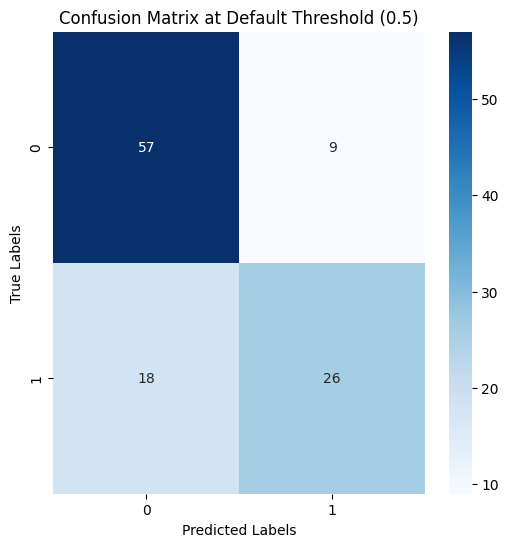

Test Accuracy: 0.7545
Test Precision: 0.7429
Test Recall: 0.5909
Test F1 Score: 0.6582


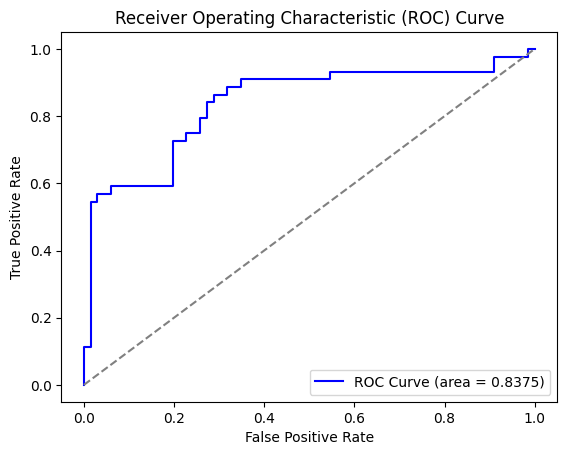

Best Threshold: 0.3121


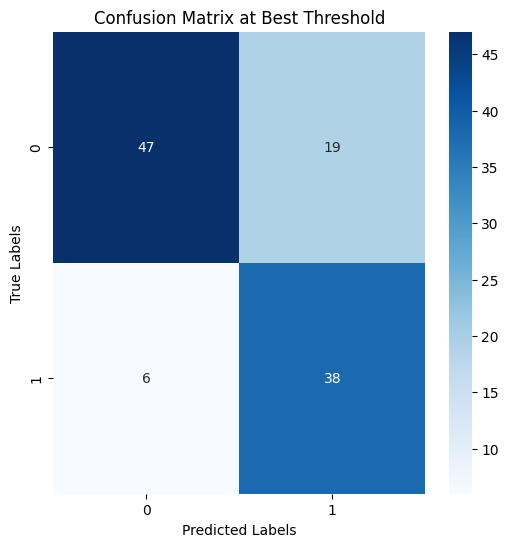

Best Threshold Accuracy: 0.7727
Best Threshold Precision: 0.6667
Best Threshold Recall: 0.8636
Best Threshold F1 Score: 0.7525


In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_curve, roc_auc_score, confusion_matrix
import numpy as np
import seaborn as sns

# Evaluate on the test set
vit_model.eval()  # Set model to evaluation mode
all_labels = []
all_preds = []
all_probs = []  # To store probabilities for ROC curve

with torch.no_grad():
    for inputs, labels in test_loader:
        inputs, labels = inputs.to(device), labels.to(device)

        # Forward pass
        outputs = vit_model(inputs)

        # Get probabilities
        probs = torch.softmax(outputs, dim=1)[:, 1]  # Get probabilities for class 1
        all_probs.extend(probs.cpu().numpy())

        # Get predictions (Default threshold 0.5)
        _, preds = torch.max(outputs, 1)

        # Store labels and predictions
        all_labels.extend(labels.cpu().numpy())
        all_preds.extend(preds.cpu().numpy())

# Confusion Matrix at Default Threshold (0.5)
conf_matrix_default = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(6, 6))
sns.heatmap(conf_matrix_default, annot=True, fmt="d", cmap="Blues", xticklabels=[0, 1], yticklabels=[0, 1])
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix at Default Threshold (0.5)')
plt.show()

# Calculate metrics at default threshold (0.5)
accuracy = accuracy_score(all_labels, all_preds)
precision = precision_score(all_labels, all_preds)
recall = recall_score(all_labels, all_preds)
f1 = f1_score(all_labels, all_preds)

print(f"Test Accuracy: {accuracy:.4f}")
print(f"Test Precision: {precision:.4f}")
print(f"Test Recall: {recall:.4f}")
print(f"Test F1 Score: {f1:.4f}")

# ROC Curve and AUC
fpr, tpr, thresholds = roc_curve(all_labels, all_probs)
roc_auc = roc_auc_score(all_labels, all_probs)

plt.figure()
plt.plot(fpr, tpr, color='blue', label=f'ROC Curve (area = {roc_auc:.4f})')
plt.plot([0, 1], [0, 1], color='gray', linestyle='--')  # Random guess line
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend(loc='lower right')
plt.show()

# Find the best threshold (closest to the top-left corner)
gmeans = np.sqrt(tpr * (1 - fpr))
ix = np.argmax(gmeans)
best_thresh = thresholds[ix]
print(f'Best Threshold: {best_thresh:.4f}')

# Apply best threshold to get new predictions
best_preds = (np.array(all_probs) >= best_thresh).astype(int)

# Confusion Matrix at Best Threshold
conf_matrix_best = confusion_matrix(all_labels, best_preds)
plt.figure(figsize=(6, 6))
sns.heatmap(conf_matrix_best, annot=True, fmt="d", cmap="Blues", xticklabels=[0, 1], yticklabels=[0, 1])
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix at Best Threshold')
plt.show()

# Calculate metrics based on best threshold
accuracy_best = accuracy_score(all_labels, best_preds)
precision_best = precision_score(all_labels, best_preds)
recall_best = recall_score(all_labels, best_preds)
f1_best = f1_score(all_labels, best_preds)

print(f"Best Threshold Accuracy: {accuracy_best:.4f}")
print(f"Best Threshold Precision: {precision_best:.4f}")
print(f"Best Threshold Recall: {recall_best:.4f}")
print(f"Best Threshold F1 Score: {f1_best:.4f}")


In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import models

# Load pretrained ViT-B/16
vit_model = models.vit_b_16(weights="DEFAULT")

# Freeze early layers (optional)
for param in vit_model.parameters():
    param.requires_grad = False

# Replace classifier head
num_ftrs = vit_model.heads.head.in_features
vit_model.heads.head = nn.Linear(num_ftrs, 2)

# Move to GPU if available
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
vit_model = vit_model.to(device)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(vit_model.heads.head.parameters(), lr=0.001)

# -----------------------------------
# STORAGE LISTS with vit_ prefix
# -----------------------------------
vit_train_losses = []
vit_val_losses = []
vit_train_accuracies = []
vit_val_accuracies = []

num_epochs = 100

for epoch in range(num_epochs):

    # -------------------------
    # TRAINING
    # -------------------------
    vit_model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for inputs, labels in train_loader:
        inputs, labels = inputs.to(device), labels.to(device)

        optimizer.zero_grad()

        outputs = vit_model(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item()

        # Accuracy
        _, predicted = torch.max(outputs, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    train_loss = running_loss / len(train_loader)
    train_acc = correct / total

    vit_train_losses.append(train_loss)
    vit_train_accuracies.append(train_acc)

    # -------------------------
    # VALIDATION
    # -------------------------
    vit_model.eval()
    val_running_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for inputs, labels in test_loader:
            inputs, labels = inputs.to(device), labels.to(device)

            outputs = vit_model(inputs)
            loss = criterion(outputs, labels)

            val_running_loss += loss.item()

            _, predicted = torch.max(outputs, 1)
            val_total += labels.size(0)
            val_correct += (predicted == labels).sum().item()

    val_loss = val_running_loss / len(test_loader)
    val_acc = val_correct / val_total

    vit_val_losses.append(val_loss)
    vit_val_accuracies.append(val_acc)

    # Print summary
    print(f"Epoch {epoch+1}/{num_epochs} | "
          f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.4f} | "
          f"Val Loss: {val_loss:.4f} | Val Acc: {val_acc:.4f}")

print("Finished Training")


Epoch 1/100 | Train Loss: 0.6881 | Train Acc: 0.5652 | Val Loss: 0.6328 | Val Acc: 0.6545
Epoch 2/100 | Train Loss: 0.6342 | Train Acc: 0.6682 | Val Loss: 0.6364 | Val Acc: 0.6273
Epoch 3/100 | Train Loss: 0.6334 | Train Acc: 0.6659 | Val Loss: 0.6016 | Val Acc: 0.7182
Epoch 4/100 | Train Loss: 0.6109 | Train Acc: 0.6865 | Val Loss: 0.5689 | Val Acc: 0.7273
Epoch 5/100 | Train Loss: 0.5973 | Train Acc: 0.6957 | Val Loss: 0.5412 | Val Acc: 0.7364
Epoch 6/100 | Train Loss: 0.5794 | Train Acc: 0.7071 | Val Loss: 0.5669 | Val Acc: 0.7727
Epoch 7/100 | Train Loss: 0.5780 | Train Acc: 0.7231 | Val Loss: 0.5377 | Val Acc: 0.7273
Epoch 8/100 | Train Loss: 0.5679 | Train Acc: 0.7140 | Val Loss: 0.5646 | Val Acc: 0.7727
Epoch 9/100 | Train Loss: 0.5591 | Train Acc: 0.7231 | Val Loss: 0.5329 | Val Acc: 0.7636
Epoch 10/100 | Train Loss: 0.5616 | Train Acc: 0.7117 | Val Loss: 0.5186 | Val Acc: 0.7727
Epoch 11/100 | Train Loss: 0.5684 | Train Acc: 0.7002 | Val Loss: 0.5264 | Val Acc: 0.7636
Epoch 12

### Swin Transformer (Swin-T)

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import models

# Load the pretrained Swin Transformer (Swin-T)
swin_model = models.swin_t(weights="DEFAULT")

# Freeze the early layers (optional)
for param in swin_model.parameters():
    param.requires_grad = False

# Replace the final fully connected layer to match the number of classes in your task
num_ftrs = swin_model.head.in_features
swin_model.head = nn.Linear(num_ftrs, 2)  # Assuming 2 classes (label 0 and label 1)

# Move the model to GPU if available
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
swin_model = swin_model.to(device)

# Define the loss function and optimizer
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(swin_model.head.parameters(), lr=0.001)

# Training the model
num_epochs = 100
for epoch in range(num_epochs):
    swin_model.train()
    running_loss = 0.0
    for inputs, labels in train_loader:
        inputs, labels = inputs.to(device), labels.to(device)

        # Zero the parameter gradients
        optimizer.zero_grad()

        # Forward pass
        outputs = swin_model(inputs)
        loss = criterion(outputs, labels)

        # Backward pass and optimize
        loss.backward()
        optimizer.step()

        # Accumulate loss
        running_loss += loss.item()

    print(f"Epoch [{epoch+1}/{num_epochs}], Loss: {running_loss/len(train_loader):.4f}")

print("Finished Training")


Epoch [1/100], Loss: 0.4003
Epoch [2/100], Loss: 0.4173
Epoch [3/100], Loss: 0.4159
Epoch [4/100], Loss: 0.4261
Epoch [5/100], Loss: 0.3924
Epoch [6/100], Loss: 0.4023
Epoch [7/100], Loss: 0.4122
Epoch [8/100], Loss: 0.3999
Epoch [9/100], Loss: 0.4043
Epoch [10/100], Loss: 0.4142
Epoch [11/100], Loss: 0.4265
Epoch [12/100], Loss: 0.4419
Epoch [13/100], Loss: 0.4155
Epoch [14/100], Loss: 0.3918
Epoch [15/100], Loss: 0.4086
Epoch [16/100], Loss: 0.4061
Epoch [17/100], Loss: 0.4097
Epoch [18/100], Loss: 0.4138
Epoch [19/100], Loss: 0.4153
Epoch [20/100], Loss: 0.3957
Epoch [21/100], Loss: 0.3937
Epoch [22/100], Loss: 0.3798
Epoch [23/100], Loss: 0.3974
Epoch [24/100], Loss: 0.4145
Epoch [25/100], Loss: 0.3977
Epoch [26/100], Loss: 0.3956
Epoch [27/100], Loss: 0.4076
Epoch [28/100], Loss: 0.4174
Epoch [29/100], Loss: 0.3976
Epoch [30/100], Loss: 0.4199
Epoch [31/100], Loss: 0.3982
Epoch [32/100], Loss: 0.3993
Epoch [33/100], Loss: 0.4180
Epoch [34/100], Loss: 0.4158
Epoch [35/100], Loss: 0

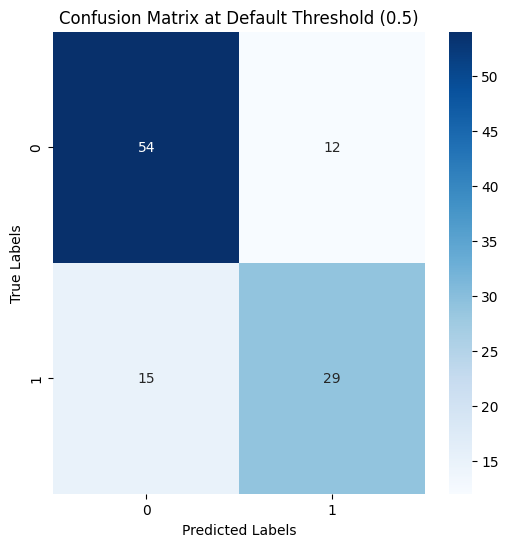

Test Accuracy: 0.7545
Test Precision: 0.7073
Test Recall: 0.6591
Test F1 Score: 0.6824


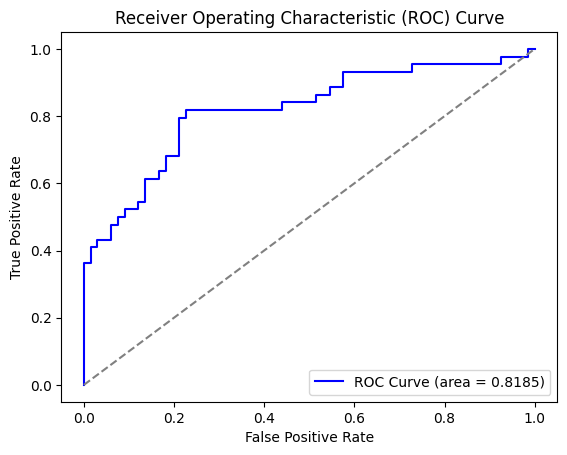

Best Threshold: 0.3262


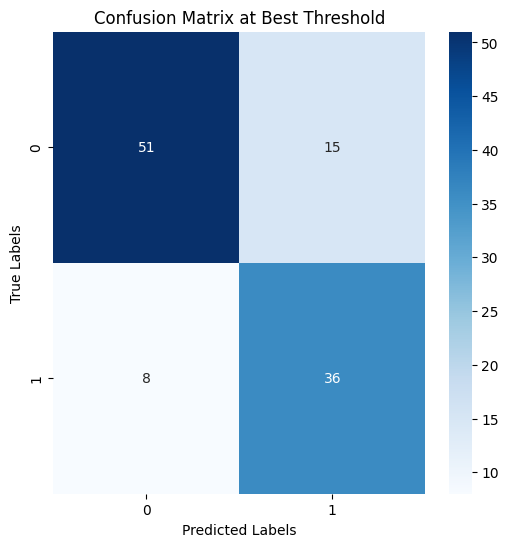

Best Threshold Accuracy: 0.7909
Best Threshold Precision: 0.7059
Best Threshold Recall: 0.8182
Best Threshold F1 Score: 0.7579


In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_curve, roc_auc_score, confusion_matrix
import numpy as np
import seaborn as sns

# Evaluate on the test set
swin_model.eval()  # Set model to evaluation mode
all_labels = []
all_preds = []
all_probs = []  # To store probabilities for ROC curve

with torch.no_grad():
    for inputs, labels in test_loader:
        inputs, labels = inputs.to(device), labels.to(device)

        # Forward pass
        outputs = swin_model(inputs)

        # Get probabilities
        probs = torch.softmax(outputs, dim=1)[:, 1]  # Get probabilities for class 1
        all_probs.extend(probs.cpu().numpy())

        # Get predictions (Default threshold 0.5)
        _, preds = torch.max(outputs, 1)

        # Store labels and predictions
        all_labels.extend(labels.cpu().numpy())
        all_preds.extend(preds.cpu().numpy())

# Confusion Matrix at Default Threshold (0.5)
conf_matrix_default = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(6, 6))
sns.heatmap(conf_matrix_default, annot=True, fmt="d", cmap="Blues", xticklabels=[0, 1], yticklabels=[0, 1])
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix at Default Threshold (0.5)')
plt.show()

# Calculate metrics at default threshold (0.5)
accuracy = accuracy_score(all_labels, all_preds)
precision = precision_score(all_labels, all_preds)
recall = recall_score(all_labels, all_preds)
f1 = f1_score(all_labels, all_preds)

print(f"Test Accuracy: {accuracy:.4f}")
print(f"Test Precision: {precision:.4f}")
print(f"Test Recall: {recall:.4f}")
print(f"Test F1 Score: {f1:.4f}")

# ROC Curve and AUC
fpr, tpr, thresholds = roc_curve(all_labels, all_probs)
roc_auc = roc_auc_score(all_labels, all_probs)

plt.figure()
plt.plot(fpr, tpr, color='blue', label=f'ROC Curve (area = {roc_auc:.4f})')
plt.plot([0, 1], [0, 1], color='gray', linestyle='--')  # Random guess line
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend(loc='lower right')
plt.show()

# Find the best threshold (closest to the top-left corner)
gmeans = np.sqrt(tpr * (1 - fpr))
ix = np.argmax(gmeans)
best_thresh = thresholds[ix]
print(f'Best Threshold: {best_thresh:.4f}')

# Apply best threshold to get new predictions
best_preds = (np.array(all_probs) >= best_thresh).astype(int)

# Confusion Matrix at Best Threshold
conf_matrix_best = confusion_matrix(all_labels, best_preds)
plt.figure(figsize=(6, 6))
sns.heatmap(conf_matrix_best, annot=True, fmt="d", cmap="Blues", xticklabels=[0, 1], yticklabels=[0, 1])
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix at Best Threshold')
plt.show()

# Calculate metrics based on best threshold
accuracy_best = accuracy_score(all_labels, best_preds)
precision_best = precision_score(all_labels, best_preds)
recall_best = recall_score(all_labels, best_preds)
f1_best = f1_score(all_labels, best_preds)

print(f"Best Threshold Accuracy: {accuracy_best:.4f}")
print(f"Best Threshold Precision: {precision_best:.4f}")
print(f"Best Threshold Recall: {recall_best:.4f}")
print(f"Best Threshold F1 Score: {f1_best:.4f}")


In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import models

# Load pretrained Swin-T
swin_model = models.swin_t(weights="DEFAULT")

# Freeze early layers (optional)
for param in swin_model.parameters():
    param.requires_grad = False

# Replace classifier head
num_ftrs = swin_model.head.in_features
swin_model.head = nn.Linear(num_ftrs, 2)

# Move to GPU
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
swin_model = swin_model.to(device)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(swin_model.head.parameters(), lr=0.001)

# ---------------------------------
# STORAGE LISTS with swin_ prefix
# ---------------------------------
swin_train_losses = []
swin_val_losses = []
swin_train_accuracies = []
swin_val_accuracies = []

num_epochs = 100

for epoch in range(num_epochs):

    # --------------------------
    # TRAINING
    # --------------------------
    swin_model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for inputs, labels in train_loader:
        inputs, labels = inputs.to(device), labels.to(device)

        optimizer.zero_grad()

        outputs = swin_model(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item()

        # Accuracy
        _, predicted = torch.max(outputs, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    train_loss = running_loss / len(train_loader)
    train_acc = correct / total

    swin_train_losses.append(train_loss)
    swin_train_accuracies.append(train_acc)

    # --------------------------
    # VALIDATION
    # --------------------------
    swin_model.eval()
    val_running_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for inputs, labels in test_loader:
            inputs, labels = inputs.to(device), labels.to(device)

            outputs = swin_model(inputs)
            loss = criterion(outputs, labels)

            val_running_loss += loss.item()

            _, predicted = torch.max(outputs, 1)
            val_total += labels.size(0)
            val_correct += (predicted == labels).sum().item()

    val_loss = val_running_loss / len(test_loader)
    val_acc = val_correct / val_total

    swin_val_losses.append(val_loss)
    swin_val_accuracies.append(val_acc)

    # Print summary
    print(f"Epoch {epoch+1}/{num_epochs} | "
          f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.4f} | "
          f"Val Loss: {val_loss:.4f} | Val Acc: {val_acc:.4f}")

print("Finished Training")


/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=Swin_T_Weights.IMAGENET1K_V1`. You can also use `weights=Swin_T_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Downloading: "https://download.pytorch.org/models/swin_t-704ceda3.pth" to /root/.cache/torch/hub/checkpoints/swin_t-704ceda3.pth


100%|██████████| 108M/108M [00:00<00:00, 159MB/s]


Epoch 1/100 | Train Loss: 0.6660 | Train Acc: 0.5721 | Val Loss: 0.5892 | Val Acc: 0.6909
Epoch 2/100 | Train Loss: 0.5512 | Train Acc: 0.7025 | Val Loss: 0.5105 | Val Acc: 0.7636
Epoch 3/100 | Train Loss: 0.5384 | Train Acc: 0.7002 | Val Loss: 0.5579 | Val Acc: 0.7091
Epoch 4/100 | Train Loss: 0.5347 | Train Acc: 0.7048 | Val Loss: 0.5038 | Val Acc: 0.7545
Epoch 5/100 | Train Loss: 0.5319 | Train Acc: 0.7277 | Val Loss: 0.5515 | Val Acc: 0.7636
Epoch 6/100 | Train Loss: 0.5162 | Train Acc: 0.7300 | Val Loss: 0.5444 | Val Acc: 0.7909
Epoch 7/100 | Train Loss: 0.5302 | Train Acc: 0.7231 | Val Loss: 0.5269 | Val Acc: 0.7364
Epoch 8/100 | Train Loss: 0.5065 | Train Acc: 0.7346 | Val Loss: 0.4857 | Val Acc: 0.7818
Epoch 9/100 | Train Loss: 0.5117 | Train Acc: 0.7277 | Val Loss: 0.4957 | Val Acc: 0.7727
Epoch 10/100 | Train Loss: 0.4990 | Train Acc: 0.7506 | Val Loss: 0.5041 | Val Acc: 0.7727
Epoch 11/100 | Train Loss: 0.4996 | Train Acc: 0.7483 | Val Loss: 0.5258 | Val Acc: 0.7727
Epoch 12

### Swin Transformer – 2-fold cross-validation

Epoch 1/100 Fold | Train Loss 0.6356 Acc 0.6777 | Val Loss 0.5852 Acc 0.6971
Epoch 2/100 Fold | Train Loss 0.5659 Acc 0.7216 | Val Loss 0.5625 Acc 0.7044
Epoch 3/100 Fold | Train Loss 0.5344 Acc 0.7253 | Val Loss 0.5613 Acc 0.7190
Epoch 4/100 Fold | Train Loss 0.5259 Acc 0.7216 | Val Loss 0.5599 Acc 0.7080
Epoch 5/100 Fold | Train Loss 0.5100 Acc 0.7436 | Val Loss 0.5695 Acc 0.7007
Epoch 6/100 Fold | Train Loss 0.5168 Acc 0.7582 | Val Loss 0.5583 Acc 0.7044
Epoch 7/100 Fold | Train Loss 0.5219 Acc 0.7509 | Val Loss 0.5626 Acc 0.7299
Epoch 8/100 Fold | Train Loss 0.5029 Acc 0.7619 | Val Loss 0.5603 Acc 0.7226
Epoch 9/100 Fold | Train Loss 0.4868 Acc 0.7656 | Val Loss 0.5585 Acc 0.7044
Epoch 10/100 Fold | Train Loss 0.4666 Acc 0.7729 | Val Loss 0.5708 Acc 0.7226
Epoch 11/100 Fold | Train Loss 0.4768 Acc 0.7619 | Val Loss 0.5661 Acc 0.6934
Epoch 12/100 Fold | Train Loss 0.4733 Acc 0.7729 | Val Loss 0.5680 Acc 0.7044
Epoch 13/100 Fold | Train Loss 0.4672 Acc 0.7766 | Val Loss 0.5661 Acc 0.

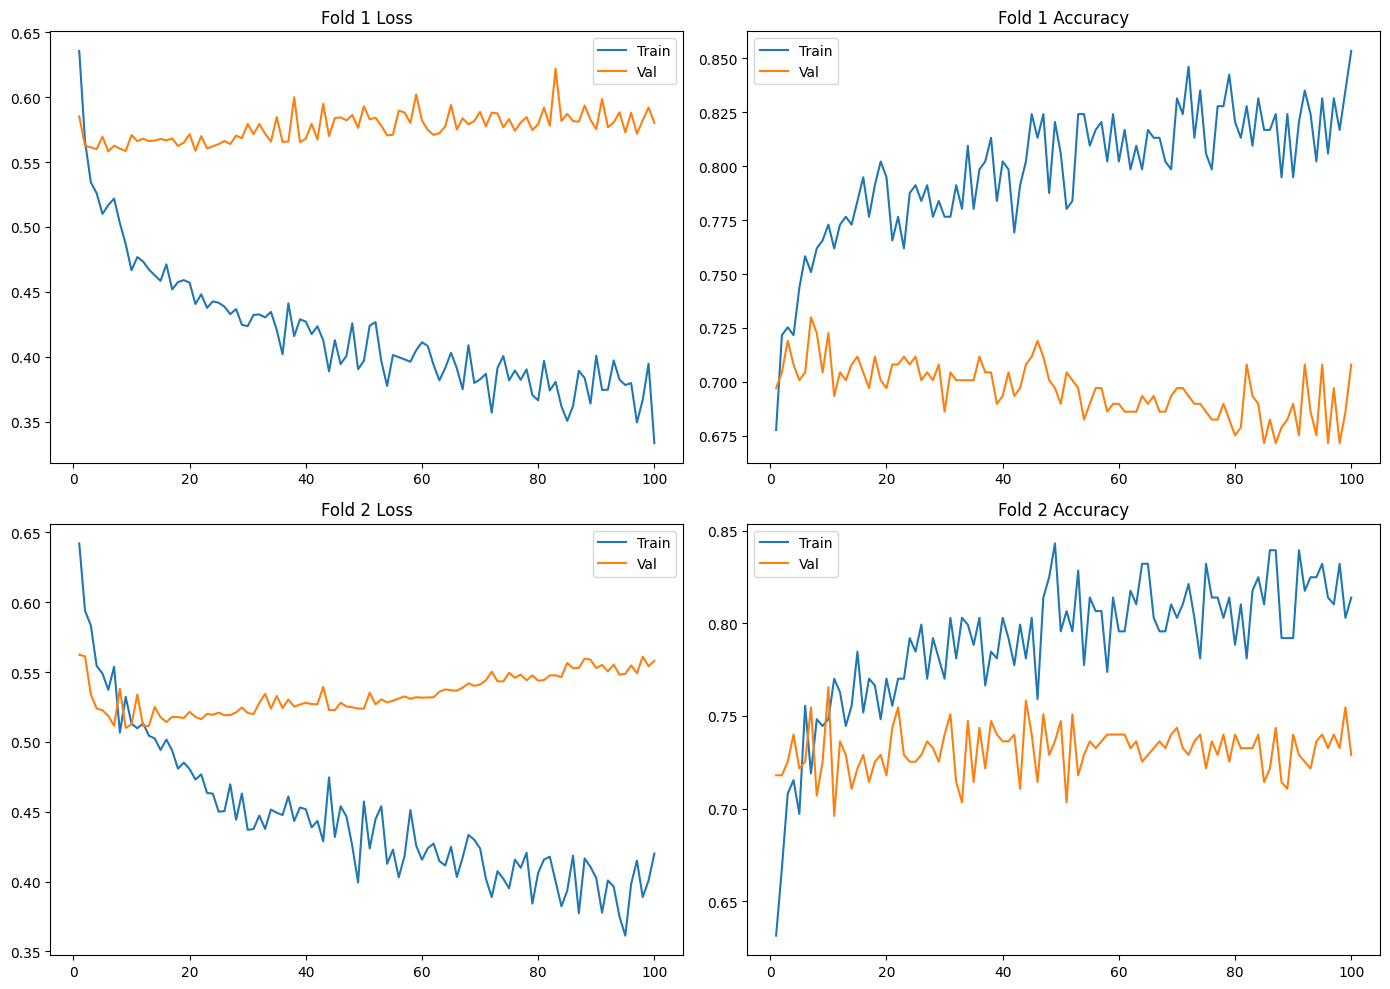

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import models
from torch.utils.data import DataLoader, Subset
from sklearn.model_selection import KFold
import matplotlib.pyplot as plt


device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

# ============================================
# 2-FOLD SPLITTING
# ============================================
kf = KFold(n_splits=2, shuffle=True, random_state=42)
folds = list(kf.split(full_dataset))

fold1_train_idx, fold1_val_idx = folds[0]
fold2_train_idx, fold2_val_idx = folds[1]

fold1_train_loader = DataLoader(Subset(full_dataset, fold1_train_idx), batch_size=32, shuffle=True)
fold1_val_loader   = DataLoader(Subset(full_dataset, fold1_val_idx), batch_size=32, shuffle=False)

fold2_train_loader = DataLoader(Subset(full_dataset, fold2_train_idx), batch_size=32, shuffle=True)
fold2_val_loader   = DataLoader(Subset(full_dataset, fold2_val_idx), batch_size=32, shuffle=False)


# ============================================
# TRAIN ONE FOLD
# ============================================
def train_one_fold(train_loader, val_loader, num_epochs=100):

    swin_model = models.swin_t(weights="DEFAULT")

    # Freeze layers
    for param in swin_model.parameters():
        param.requires_grad = False

    # Replace head
    num_ftrs = swin_model.head.in_features
    swin_model.head = nn.Linear(num_ftrs, 2)
    swin_model = swin_model.to(device)

    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(swin_model.head.parameters(), lr=0.001)

    train_losses, val_losses = [], []
    train_accs, val_accs = [], []

    for epoch in range(num_epochs):

        # -------- TRAIN ----------
        swin_model.train()
        running_loss, total, correct = 0.0, 0, 0

        for imgs, labels in train_loader:
            imgs, labels = imgs.to(device), labels.to(device)

            optimizer.zero_grad()
            outputs = swin_model(imgs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item()
            _, pred = torch.max(outputs, 1)
            total += labels.size(0)
            correct += (pred == labels).sum().item()

        train_losses.append(running_loss / len(train_loader))
        train_accs.append(correct / total)

        # -------- VAL ----------
        swin_model.eval()
        vloss, vtotal, vcorrect = 0.0, 0, 0

        with torch.no_grad():
            for imgs, labels in val_loader:
                imgs, labels = imgs.to(device), labels.to(device)
                outputs = swin_model(imgs)

                loss = criterion(outputs, labels)
                vloss += loss.item()

                _, pred = torch.max(outputs, 1)
                vtotal += labels.size(0)
                vcorrect += (pred == labels).sum().item()

        val_losses.append(vloss / len(val_loader))
        val_accs.append(vcorrect / vtotal)

        print(f"Epoch {epoch+1}/{num_epochs} Fold | "
              f"Train Loss {train_losses[-1]:.4f} Acc {train_accs[-1]:.4f} | "
              f"Val Loss {val_losses[-1]:.4f} Acc {val_accs[-1]:.4f}")

    return train_losses, val_losses, train_accs, val_accs


# ============================================
# RUN BOTH FOLDS
# ============================================
fold1_train_losses, fold1_val_losses, fold1_train_acc, fold1_val_acc = \
    train_one_fold(fold1_train_loader, fold1_val_loader)

fold2_train_losses, fold2_val_losses, fold2_train_acc, fold2_val_acc = \
    train_one_fold(fold2_train_loader, fold2_val_loader)


# ============================================
# PLOTS (2x2 SUBPLOT)
# ============================================
epochs1 = range(1, len(fold1_train_losses) + 1)
epochs2 = range(1, len(fold2_train_losses) + 1)

fig, ax = plt.subplots(2, 2, figsize=(14, 10))

# Fold 1 Loss
ax[0, 0].plot(epochs1, fold1_train_losses, label="Train")
ax[0, 0].plot(epochs1, fold1_val_losses, label="Val")
ax[0, 0].set_title("Fold 1 Loss")
ax[0, 0].legend()

# Fold 1 Accuracy
ax[0, 1].plot(epochs1, fold1_train_acc, label="Train")
ax[0, 1].plot(epochs1, fold1_val_acc, label="Val")
ax[0, 1].set_title("Fold 1 Accuracy")
ax[0, 1].legend()

# Fold 2 Loss
ax[1, 0].plot(epochs2, fold2_train_losses, label="Train")
ax[1, 0].plot(epochs2, fold2_val_losses, label="Val")
ax[1, 0].set_title("Fold 2 Loss")
ax[1, 0].legend()

# Fold 2 Accuracy
ax[1, 1].plot(epochs2, fold2_train_acc, label="Train")
ax[1, 1].plot(epochs2, fold2_val_acc, label="Val")
ax[1, 1].set_title("Fold 2 Accuracy")
ax[1, 1].legend()

plt.tight_layout()
plt.show()


### Comparison: training/validation curves

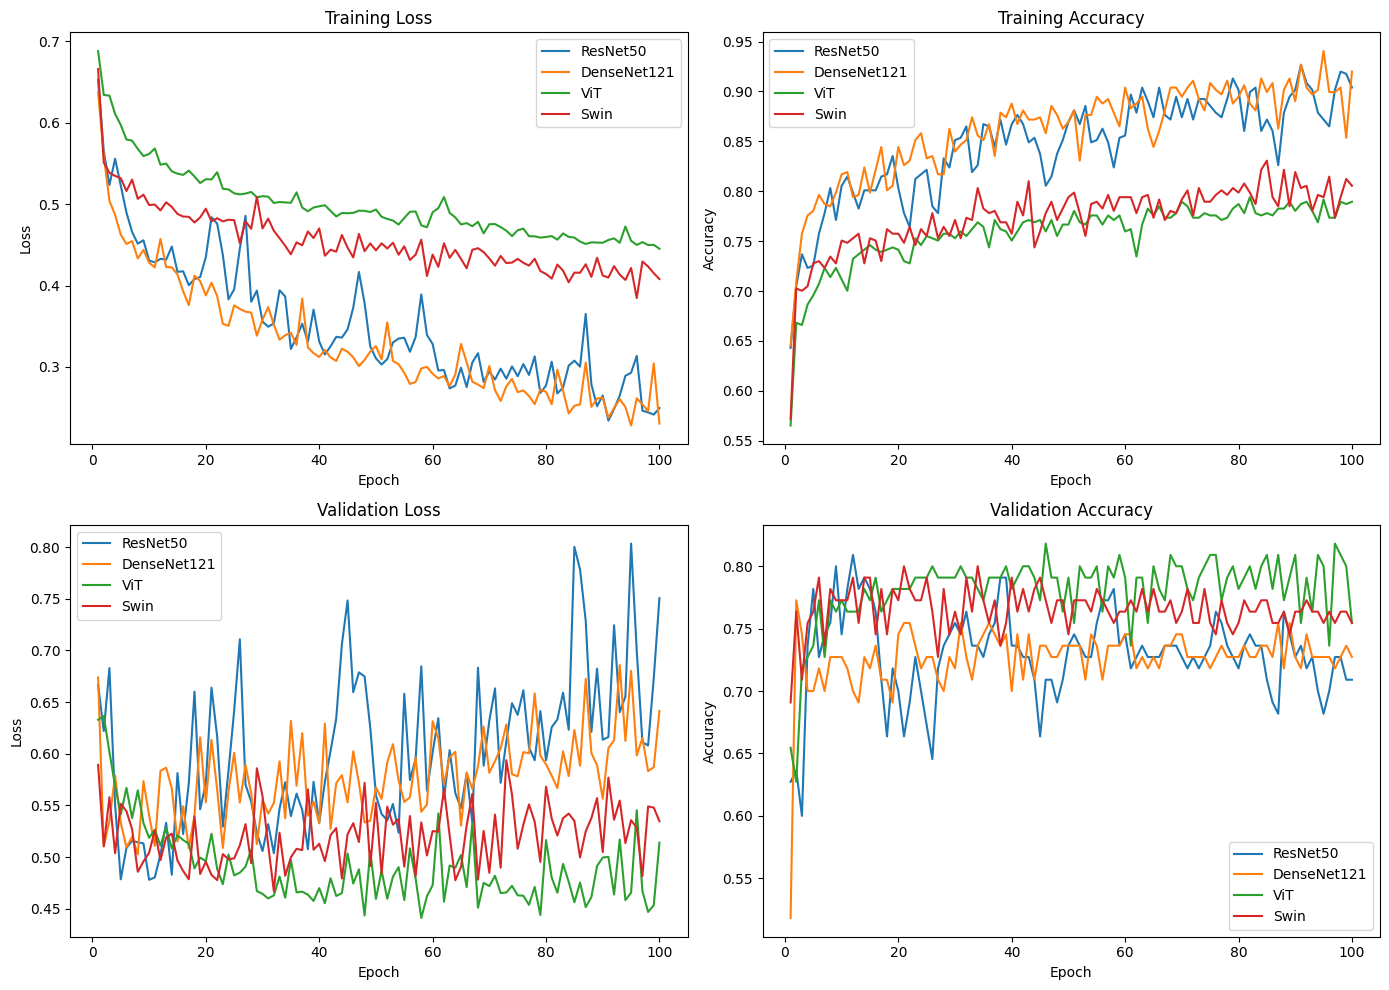

In [ ]:
import matplotlib.pyplot as plt

# Put ALL your metric lists here
model_metrics = {
    "ResNet50": {
        "train_loss": resnet_train_losses,
        "train_acc": resnet_train_accuracies,
        "val_loss": resnet_val_losses,
        "val_acc": resnet_val_accuracies
    },
    "DenseNet121": {
        "train_loss": densenet_train_losses,
        "train_acc": densenet_train_accuracies,
        "val_loss": densenet_val_losses,
        "val_acc": densenet_val_accuracies
    },
    "ViT": {
        "train_loss": vit_train_losses,
        "train_acc": vit_train_accuracies,
        "val_loss": vit_val_losses,
        "val_acc": vit_val_accuracies
    },
    "Swin": {
        "train_loss": swin_train_losses,
        "train_acc": swin_train_accuracies,
        "val_loss": swin_val_losses,
        "val_acc": swin_val_accuracies
    }
}

epochs = range(1, len(resnet_train_losses) + 1)

fig, axs = plt.subplots(2, 2, figsize=(14, 10))

# -------------------------
# Row 1, Col 1: Training Loss
# -------------------------
for name, m in model_metrics.items():
    axs[0, 0].plot(epochs, m["train_loss"], label=name)
axs[0, 0].set_title("Training Loss")
axs[0, 0].set_xlabel("Epoch")
axs[0, 0].set_ylabel("Loss")
axs[0, 0].legend()

# -------------------------
# Row 1, Col 2: Training Accuracy
# -------------------------
for name, m in model_metrics.items():
    axs[0, 1].plot(epochs, m["train_acc"], label=name)
axs[0, 1].set_title("Training Accuracy")
axs[0, 1].set_xlabel("Epoch")
axs[0, 1].set_ylabel("Accuracy")
axs[0, 1].legend()

# -------------------------
# Row 2, Col 1: Validation Loss
# -------------------------
for name, m in model_metrics.items():
    axs[1, 0].plot(epochs, m["val_loss"], label=name)
axs[1, 0].set_title("Validation Loss")
axs[1, 0].set_xlabel("Epoch")
axs[1, 0].set_ylabel("Loss")
axs[1, 0].legend()

# -------------------------
# Row 2, Col 2: Validation Accuracy
# -------------------------
for name, m in model_metrics.items():
    axs[1, 2-1].plot(epochs, m["val_acc"], label=name)
axs[1, 1].set_title("Validation Accuracy")
axs[1, 1].set_xlabel("Epoch")
axs[1, 1].set_ylabel("Accuracy")
axs[1, 1].legend()

plt.tight_layout()
plt.show()


### Comparison: training loss (recorded values)

In [ ]:
resnet_50 = [
    0.7278, 0.6018, 0.5323, 0.5106, 0.5132, 0.5248, 0.4867, 0.4672, 0.4750, 0.4460,
    0.4406, 0.4407, 0.4549, 0.4182, 0.3907, 0.4670, 0.4366, 0.4098, 0.3910, 0.4141,
    0.4045, 0.3953, 0.3815, 0.3856, 0.3905, 0.3886, 0.3823, 0.3648, 0.3966, 0.4143,
    0.3867, 0.3882, 0.3538, 0.3562, 0.3511, 0.3514, 0.3413, 0.3460, 0.3316, 0.3538,
    0.3427, 0.3316, 0.3250, 0.4295, 0.3303, 0.3538, 0.3397, 0.3091, 0.3302, 0.3497,
    0.3287, 0.3139, 0.3701, 0.3825, 0.3541, 0.3382, 0.3234, 0.2957, 0.2848, 0.2942,
    0.2953, 0.3091, 0.2965, 0.2911, 0.3086, 0.3027, 0.3027, 0.3675, 0.3274, 0.3141,
    0.2687, 0.3182, 0.3109, 0.2987, 0.2934, 0.3496, 0.3096, 0.2764, 0.2894, 0.2783,
    0.2922, 0.2692, 0.2638, 0.2965, 0.2837, 0.2562, 0.2761, 0.2480, 0.2738, 0.2516,
    0.2410, 0.2763, 0.2344, 0.2659, 0.2361, 0.2736, 0.2618, 0.2616, 0.2400, 0.2585
]

densenet_121 = [
    0.6573, 0.5511, 0.5096, 0.4890, 0.4730, 0.4683, 0.4882, 0.4638, 0.4377, 0.4537,
    0.4242, 0.4187, 0.4022, 0.4010, 0.3900, 0.4211, 0.3970, 0.3761, 0.3954, 0.3941,
    0.4147, 0.3883, 0.3688, 0.3716, 0.3427, 0.3597, 0.3593, 0.3472, 0.3565, 0.3586,
    0.3510, 0.3329, 0.3563, 0.3340, 0.3246, 0.3304, 0.3280, 0.3348, 0.3658, 0.3376,
    0.3365, 0.3152, 0.2998, 0.3033, 0.3404, 0.3295, 0.3411, 0.3341, 0.3318, 0.3033,
    0.3102, 0.3080, 0.3130, 0.2972, 0.3062, 0.2986, 0.2800, 0.2825, 0.2759, 0.3179,
    0.3383, 0.3015, 0.3176, 0.2725, 0.2776, 0.2914, 0.2742, 0.2785, 0.2608, 0.3029,
    0.2691, 0.2761, 0.2732, 0.2723, 0.2962, 0.2729, 0.2673, 0.3033, 0.2830, 0.2378,
    0.2947, 0.2831, 0.2791, 0.2718, 0.2931, 0.2469, 0.2663, 0.2923, 0.2582, 0.2661,
    0.2757, 0.2724, 0.2720, 0.2655, 0.2247, 0.2600, 0.2549, 0.2868, 0.2515, 0.2997
]

vision_transformer = [
    0.6538, 0.6244, 0.6041, 0.6070, 0.5944, 0.5762, 0.5656, 0.5578, 0.5571, 0.5521,
    0.5609, 0.5561, 0.5437, 0.5501, 0.5412, 0.5287, 0.5300, 0.5351, 0.5311, 0.5230,
    0.5250, 0.5276, 0.5487, 0.5441, 0.5202, 0.5145, 0.5113, 0.5138, 0.5196, 0.5155,
    0.5125, 0.5073, 0.5144, 0.5175, 0.5020, 0.5011, 0.5004, 0.5021, 0.5127, 0.4981,
    0.4952, 0.4881, 0.4959, 0.4891, 0.4852, 0.4893, 0.4854, 0.4902, 0.4847, 0.4870,
    0.4826, 0.4895, 0.4833, 0.4869, 0.4804, 0.4902, 0.4811, 0.4983, 0.4744, 0.4767,
    0.4704, 0.4698, 0.4837, 0.4655, 0.4760, 0.4695, 0.4770, 0.4682, 0.4671, 0.4724,
    0.4684, 0.4596, 0.4671, 0.4627, 0.4680, 0.4689, 0.4654, 0.4688, 0.4680, 0.4665,
    0.4639, 0.4636, 0.4550, 0.4530, 0.4610, 0.4528, 0.4597, 0.4705, 0.4528, 0.4506,
    0.4493, 0.4524, 0.4484, 0.4532, 0.4467, 0.4519, 0.4478, 0.4465, 0.4455, 0.4707
]

swin_transformer = [
    0.6215, 0.5538, 0.5473, 0.5286, 0.5180, 0.5294, 0.5077, 0.5235, 0.5120, 0.5045,
    0.4988, 0.5089, 0.4738, 0.4928, 0.4842, 0.4884, 0.4711, 0.4738, 0.4782, 0.5022,
    0.4713, 0.4826, 0.4652, 0.4869, 0.4678, 0.4690, 0.4583, 0.4868, 0.4753, 0.4698,
    0.4467, 0.4687, 0.4755, 0.4674, 0.4660, 0.4585, 0.4436, 0.4423, 0.4642, 0.4612,
    0.4540, 0.4591, 0.4458, 0.4368, 0.4319, 0.4360, 0.4558, 0.4345, 0.4421, 0.4343,
    0.4308, 0.4498, 0.4304, 0.4257, 0.4496, 0.4526, 0.4307, 0.4443, 0.4512, 0.4541,
    0.4368, 0.4508, 0.4265, 0.4441, 0.4214, 0.4447, 0.4341, 0.4164, 0.4208, 0.4324,
    0.4257, 0.4270, 0.4183, 0.4255, 0.4361, 0.4330, 0.4190, 0.4253, 0.4069, 0.4487,
    0.4232, 0.4263, 0.4311, 0.4237, 0.4108, 0.4277, 0.4436, 0.4340, 0.4202, 0.3989,
    0.4046, 0.4023, 0.4083, 0.4193, 0.3941, 0.4128, 0.4029, 0.4089, 0.4372, 0.4127
]


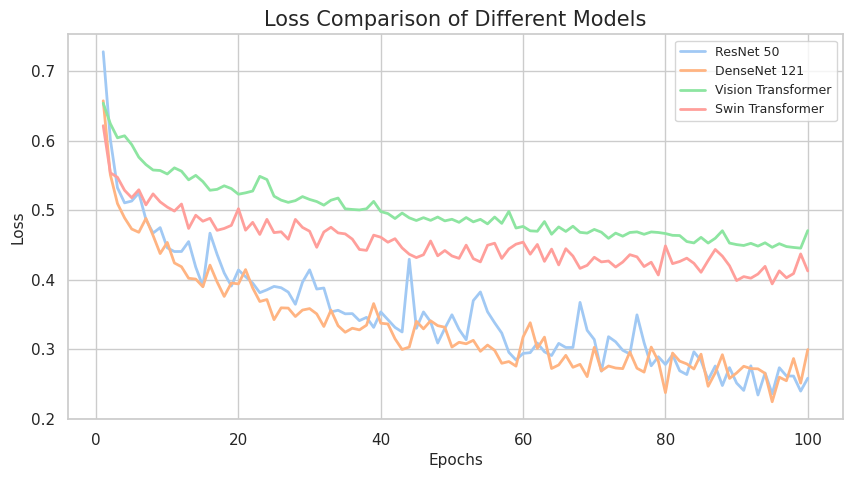

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Number of epochs (assuming 100)
epochs = range(1, 101)

# Plot settings
sns.set(style="whitegrid")
palette = sns.color_palette("pastel")

# Plotting the losses
plt.figure(figsize=(10, 5))
plt.plot(epochs, resnet_50, label="ResNet 50", color=palette[0], linewidth=2)
plt.plot(epochs, densenet_121, label="DenseNet 121", color=palette[1], linewidth=2)
plt.plot(epochs, vision_transformer, label="Vision Transformer", color=palette[2], linewidth=2)
plt.plot(epochs, swin_transformer, label="Swin Transformer", color=palette[3], linewidth=2)

# Labels and title
plt.xlabel("Epochs", fontsize=11)
plt.ylabel("Loss", fontsize=11)
plt.title("Loss Comparison of Different Models", fontsize=15)
plt.legend(fontsize=9)

# Show plot
plt.show()


## 2. Tabular Eye-Tracking Features

### Feature extraction

In [ ]:
import os
import pandas as pd

# Directory containing the CSV files
csv_directory = str(DATA_DIR / 'Eye-Tracking Dataset/Eye-tracking Output')

# List to hold data from each CSV file
data_frames = []

# Loop through each file in the directory
for filename in os.listdir(csv_directory):
    if filename.endswith(".csv"):
        # Construct full file path
        file_path = os.path.join(csv_directory, filename)
        # Read the CSV file
        df = pd.read_csv(file_path)
        # Append to the list
        data_frames.append(df)

# Combine all dataframes into one (optional)
combined_df = pd.concat(data_frames, ignore_index=True)


/tmp/ipython-input-661493469.py:16: DtypeWarning: Columns (7,15,16,17,18,19,20,21,22,23,24,27,28,29,30,31,32,33,34,35,36,37,38,39,40,41,42) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(file_path)
/tmp/ipython-input-661493469.py:16: DtypeWarning: Columns (7) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(file_path)
/tmp/ipython-input-661493469.py:16: DtypeWarning: Columns (7) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(file_path)
/tmp/ipython-input-661493469.py:16: DtypeWarning: Columns (7) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(file_path)
/tmp/ipython-input-661493469.py:16: DtypeWarning: Columns (7) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(file_path)
/tmp/ipython-input-661493469.py:16: DtypeWarning: Columns (7) have mixed types. Specify dtyp

In [ ]:
combined_df

,Unnamed: 0,RecordingTime [ms],Time of Day [h:m:s:ms],Trial,Stimulus,Export Start Trial Time [ms],Export End Trial Time [ms],Participant,Color,Tracking Ratio [%],...,Scroll Direction Y,Content,AOI Group Right,AOI Scope Right,AOI Order Right,AOI Group Left,AOI Scope Left,AOI Order Binocular,Port Status,groupe d'enfants
0,0,2080377.213,08:42:06:353,Trial020,Eye Tracking (ballon droite).avi,0.0,52046.827,Unidentified(Neg),Goldenrod,63.7887,...,-,eye tracking (ballon droite).avi,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1,2080416.778,08:42:06:393,Trial020,Eye Tracking (ballon droite).avi,0.0,52046.827,Unidentified(Neg),Goldenrod,63.7887,...,-,-,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2,2080558.752,08:42:06:535,Trial020,Eye Tracking (ballon droite).avi,0.0,52046.827,Unidentified(Neg),Goldenrod,63.7887,...,-,-,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,3,2080642.772,08:42:06:619,Trial020,Eye Tracking (ballon droite).avi,0.0,52046.827,Unidentified(Neg),Goldenrod,63.7887,...,-,-,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,4,2080924.649,08:42:06:900,Trial020,Eye Tracking (ballon droite).avi,0.0,52046.827,Unidentified(Neg),Goldenrod,63.7887,...,-,-,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2252938,130904,2571408.794,17:40:50:907,Trial019,Eye Tracking (ballon droite).avi,0.0,52239.407,Unidentified(Neg),Pink,79.1867,...,-,-,-,-,-,-,-,-,0,NaN
2252939,130905,2571425.491,17:40:50:924,Trial019,Eye Tracking (ballon droite).avi,0.0,52239.407,Unidentified(Neg),Pink,79.1867,...,-,-,-,-,-,-,-,-,0,NaN
2252940,130906,2571442.185,17:40:50:940,Trial019,Eye Tracking (ballon droite).avi,0.0,52239.407,Unidentified(Neg),Pink,79.1867,...,-,-,-,-,-,-,-,-,0,NaN
2252941,130907,2571458.879,17:40:50:957,Trial019,Eye Tracking (ballon droite).avi,0.0,52239.407,Unidentified(Neg),Pink,79.1867,...,-,-,-,-,-,-,-,-,0,NaN


In [ ]:
combined_df = combined_df[~combined_df["Participant"].isin(["Unidentified(Neg)", "Unidentified(Pos)"])]
combined_df["Participant"] = pd.to_numeric(combined_df["Participant"], errors='coerce')

combined_df = combined_df[(combined_df["Category Group"] == "Eye") | (combined_df["Category Group"] == "eye")]
combined_df = combined_df[['Participant','Tracking Ratio [%]', 'Category Right', 'Category Left',
                          'Pupil Size Right X [px]',
                          'Pupil Size Right Y [px]', 'Pupil Diameter Right [mm]',
                          'Pupil Size Left X [px]', 'Pupil Size Left Y [px]',
                          'Pupil Diameter Left [mm]', 'Point of Regard Right X [px]',
                          'Point of Regard Right Y [px]', 'Point of Regard Left X [px]',
                          'Point of Regard Left Y [px]']]


combined_df = combined_df[(combined_df["Category Right"] != "Separator")
 & (combined_df["Category Left"] != "Separator")
 & (combined_df["Category Right"] != "-")
 & (combined_df["Category Left"] != "-")]

/tmp/ipython-input-947768781.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  combined_df["Participant"] = pd.to_numeric(combined_df["Participant"], errors='coerce')


In [ ]:
import pandas as pd

rows_with_missing_values = combined_df.isna().any(axis=1).sum()

# Print the result
print(f"Number of rows with missing values: {rows_with_missing_values}")
print("Percentage of missing value: ", rows_with_missing_values/len(combined_df))


In [ ]:
combined_df = combined_df.dropna()

In [ ]:
combined_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 630865 entries, 1829 to 2122033
Data columns (total 14 columns):
 #   Column                        Non-Null Count   Dtype  
---  ------                        --------------   -----  
 0   Participant                   630865 non-null  int64  
 1   Tracking Ratio [%]            630865 non-null  float64
 2   Category Right                630865 non-null  object 
 3   Category Left                 630865 non-null  object 
 4   Pupil Size Right X [px]       630865 non-null  object 
 5   Pupil Size Right Y [px]       630865 non-null  object 
 6   Pupil Diameter Right [mm]     630865 non-null  object 
 7   Pupil Size Left X [px]        630865 non-null  object 
 8   Pupil Size Left Y [px]        630865 non-null  object 
 9   Pupil Diameter Left [mm]      630865 non-null  object 
 10  Point of Regard Right X [px]  630865 non-null  object 
 11  Point of Regard Right Y [px]  630865 non-null  object 
 12  Point of Regard Left X [px]   630865 non-null

In [ ]:
# List of columns to exclude from conversion
exclude_columns = ['Category Right', 'Category Left', 'Participant']

# Loop through each column, and if it's not in the exclude list, try converting to float
for col in combined_df.columns:
    if col not in exclude_columns:
        combined_df[col] = pd.to_numeric(combined_df[col], errors='coerce')

# Check the result
print(combined_df.dtypes)


Participant                       int64
Tracking Ratio [%]              float64
Category Right                   object
Category Left                    object
Pupil Size Right X [px]         float64
Pupil Size Right Y [px]         float64
Pupil Diameter Right [mm]       float64
Pupil Size Left X [px]          float64
Pupil Size Left Y [px]          float64
Pupil Diameter Left [mm]        float64
Point of Regard Right X [px]    float64
Point of Regard Right Y [px]    float64
Point of Regard Left X [px]     float64
Point of Regard Left Y [px]     float64
dtype: object


In [ ]:
# Step 1: Exclude rows where 'Category Right' or 'Category Left' is 'Blink'
filtered_df = combined_df[(combined_df['Category Right'] != 'Blink') & (combined_df['Category Left'] != 'Blink')]

# Ensure the relevant columns are numeric, coerce errors to NaN
columns_to_calculate = [
    'Pupil Size Right X [px]', 'Pupil Size Right Y [px]',
    'Pupil Diameter Right [mm]', 'Pupil Size Left X [px]', 'Pupil Size Left Y [px]', 'Pupil Diameter Left [mm]',
    'Point of Regard Right X [px]', 'Point of Regard Right Y [px]', 'Point of Regard Left X [px]', 'Point of Regard Left Y [px]'
]

# Convert columns to numeric, forcing errors to NaN
for column in columns_to_calculate:
    filtered_df[column] = pd.to_numeric(filtered_df[column], errors='coerce')

# Step 2: Count total rows for each Participant
total_rows_per_participant = combined_df.groupby('Participant').size()

# Step 3: Calculate the proportion of each Category Right and Category Left type (excluding 'Blink')
category_right_counts = filtered_df[filtered_df['Category Right'].isin(["Saccade", "Fixation"])].groupby(['Participant', 'Category Right']).size().unstack(fill_value=0)
category_left_counts = filtered_df[filtered_df['Category Left'].isin(["Saccade", "Fixation"])].groupby(['Participant', 'Category Left']).size().unstack(fill_value=0)

# Step 4: Divide the counts by the total number of rows for each participant
# Right Eye Proportions
category_right_counts['Saccade_Right'] = category_right_counts['Saccade'] / total_rows_per_participant
category_right_counts['Fixation_Right'] = category_right_counts['Fixation'] / total_rows_per_participant

# Left Eye Proportions
category_left_counts['Saccade_Left'] = category_left_counts['Saccade'] / total_rows_per_participant
category_left_counts['Fixation_Left'] = category_left_counts['Fixation'] / total_rows_per_participant

# Step 5: Reset index and combine the two sets of columns (Right and Left) into a single DataFrame
category_right_counts = category_right_counts[['Saccade_Right', 'Fixation_Right']].reset_index().fillna(0)
category_left_counts = category_left_counts[['Saccade_Left', 'Fixation_Left']].reset_index().fillna(0)

# Merge Right and Left data on Participant
final_df = pd.merge(category_right_counts, category_left_counts, on='Participant', how='outer').fillna(0)

# Step 6: Calculate mean, median, and standard deviation for the specified columns (excluding 'Blink')
# Group by Participant and calculate mean, median, and standard deviation
agg_stats = filtered_df.groupby('Participant')[columns_to_calculate].agg(['mean', 'median', 'std'])

# Flatten multi-level columns
agg_stats.columns = ['_'.join(col).strip() for col in agg_stats.columns.values]

# Reset index to include Participant as a column
agg_stats = agg_stats.reset_index()

# Merge aggregated stats with the final_df containing proportions
final_combined_df = pd.merge(final_df, agg_stats, on='Participant', how='outer')


/tmp/ipython-input-2400893567.py:13: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  filtered_df[column] = pd.to_numeric(filtered_df[column], errors='coerce')


In [ ]:
final_combined_df.columns

Index(['Participant', 'Saccade_Right', 'Fixation_Right', 'Saccade_Left',
       'Fixation_Left', 'Pupil Size Right X [px]_mean',
       'Pupil Size Right X [px]_median', 'Pupil Size Right X [px]_std',
       'Pupil Size Right Y [px]_mean', 'Pupil Size Right Y [px]_median',
       'Pupil Size Right Y [px]_std', 'Pupil Diameter Right [mm]_mean',
       'Pupil Diameter Right [mm]_median', 'Pupil Diameter Right [mm]_std',
       'Pupil Size Left X [px]_mean', 'Pupil Size Left X [px]_median',
       'Pupil Size Left X [px]_std', 'Pupil Size Left Y [px]_mean',
       'Pupil Size Left Y [px]_median', 'Pupil Size Left Y [px]_std',
       'Pupil Diameter Left [mm]_mean', 'Pupil Diameter Left [mm]_median',
       'Pupil Diameter Left [mm]_std', 'Point of Regard Right X [px]_mean',
       'Point of Regard Right X [px]_median',
       'Point of Regard Right X [px]_std', 'Point of Regard Right Y [px]_mean',
       'Point of Regard Right Y [px]_median',
       'Point of Regard Right Y [px]_std', 'Po

In [ ]:
len(final_combined_df.columns)

35

In [ ]:
final_combined_df

,Participant,Saccade_Right,Fixation_Right,Saccade_Left,Fixation_Left,Pupil Size Right X [px]_mean,Pupil Size Right X [px]_median,Pupil Size Right X [px]_std,Pupil Size Right Y [px]_mean,Pupil Size Right Y [px]_median,...,Point of Regard Right X [px]_std,Point of Regard Right Y [px]_mean,Point of Regard Right Y [px]_median,Point of Regard Right Y [px]_std,Point of Regard Left X [px]_mean,Point of Regard Left X [px]_median,Point of Regard Left X [px]_std,Point of Regard Left Y [px]_mean,Point of Regard Left Y [px]_median,Point of Regard Left Y [px]_std
0,1,0.094713,0.746663,0.094713,0.746663,15.445401,15.48725,1.142092,15.445401,15.48725,...,204.212708,421.453600,396.01710,111.325835,651.739726,645.27105,204.212708,421.453600,396.01710,111.325835
1,2,0.130409,0.745322,0.132749,0.742982,17.126199,17.17260,2.685986,17.039054,17.17260,...,270.925826,515.916749,377.42030,286.455713,537.346236,588.42260,270.925826,515.916749,377.42030,286.455713
2,3,0.074856,0.850517,0.076005,0.849369,19.862984,19.92485,1.562818,19.862984,19.92485,...,256.812251,387.608693,366.23140,86.908303,625.903996,622.04125,256.812251,387.608693,366.23140,86.908303
3,4,0.111438,0.783982,0.112907,0.782513,18.515167,18.48090,1.671281,18.508329,18.48090,...,283.202901,537.276477,411.06670,257.433116,706.154286,632.96310,283.202901,537.276477,411.06670,257.433116
4,5,0.103796,0.810428,0.101874,0.812350,13.891402,14.32500,1.948185,13.880889,14.32500,...,328.908200,389.605414,372.28630,127.011424,654.258285,662.98960,328.908200,389.605414,372.28630,127.011424
5,6,0.093501,0.853364,0.093044,0.853820,21.449833,21.58170,1.809461,21.449833,21.58170,...,286.598322,413.484158,385.13570,126.265530,692.480767,667.69450,286.598322,413.484158,385.13570,126.265530
6,7,0.175714,0.441429,0.177500,0.439643,20.954489,21.04915,2.385616,20.954489,21.04915,...,293.431495,375.923989,368.53120,134.409575,632.331159,654.60490,293.431495,375.923989,368.53120,134.409575
7,8,0.049559,0.107379,0.051211,0.105727,15.277348,15.34350,2.239562,15.277348,15.34350,...,378.009113,751.963411,921.04530,326.302115,820.389142,915.31010,378.009113,751.963411,921.04530,326.302115
8,9,0.020449,0.016161,0.018799,0.017810,14.614115,15.24450,2.714611,14.614115,15.24450,...,138.893616,136.912535,149.42310,161.390382,258.459609,281.29240,138.893616,136.912535,149.42310,161.390382
9,10,0.075870,0.873401,0.075870,0.873401,15.204757,15.31270,1.080885,15.204757,15.31270,...,188.141187,407.053325,363.40270,141.986380,629.172615,622.89320,188.141187,407.053325,363.40270,141.986380


### Neural Network

Epoch 10/100 | Train Loss: 1.1294 | Val Loss: 0.5709
Epoch 20/100 | Train Loss: 0.6785 | Val Loss: 0.4203
Epoch 30/100 | Train Loss: 0.5575 | Val Loss: 0.4234
Epoch 40/100 | Train Loss: 0.4967 | Val Loss: 0.3522
Epoch 50/100 | Train Loss: 0.4646 | Val Loss: 0.3495
Epoch 60/100 | Train Loss: 0.4444 | Val Loss: 0.3627
Epoch 70/100 | Train Loss: 0.4326 | Val Loss: 0.3662
Epoch 80/100 | Train Loss: 0.4203 | Val Loss: 0.3732
Epoch 90/100 | Train Loss: 0.4092 | Val Loss: 0.3637
Epoch 100/100 | Train Loss: 0.3989 | Val Loss: 0.3553


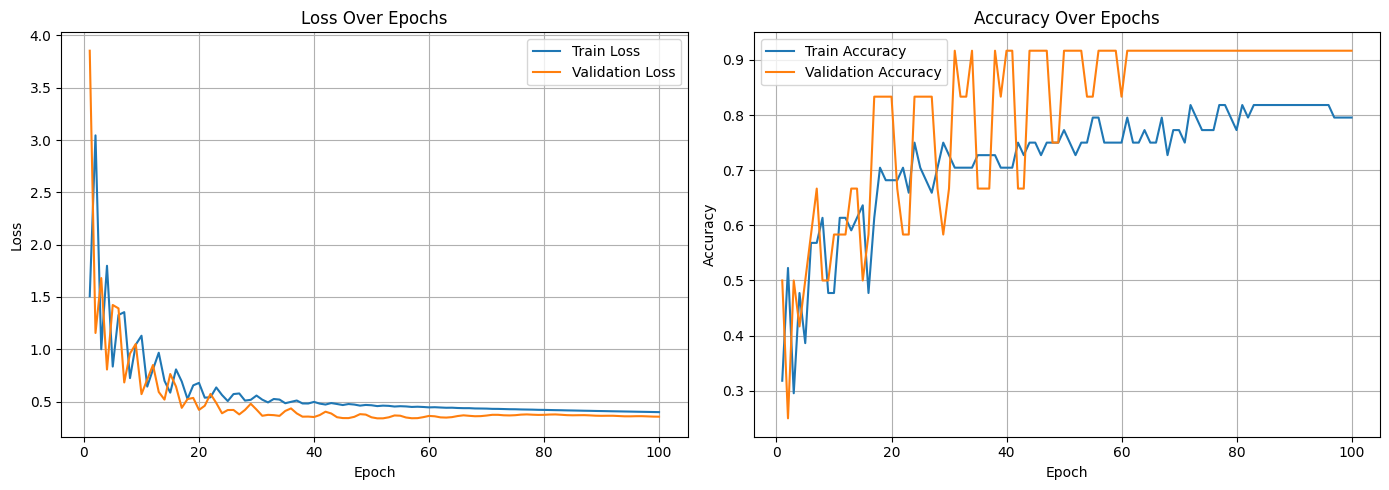

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, roc_auc_score, accuracy_score, precision_score, recall_score, f1_score, roc_curve
import matplotlib.pyplot as plt
import seaborn as sns

# Step 1: Add the label column
final_combined_df['label'] = final_combined_df['Participant'].apply(lambda x: 1 if 1 <= x <= 29 else 0)

# Step 2: Split into features and target
X = final_combined_df.drop(columns=['label', 'Participant']).values  # Convert to NumPy array
y = final_combined_df['label'].values  # Convert to NumPy array

# Step 3: Train-test split (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Step 4: Define the neural network architecture
class NeuralNet(nn.Module):
    def __init__(self, input_size):
        super(NeuralNet, self).__init__()
        self.fc1 = nn.Linear(input_size, 64)  # First hidden layer
        self.fc2 = nn.Linear(64, 32)  # Second hidden layer
        self.fc3 = nn.Linear(32, 1)   # Output layer (1 for binary classification)
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        x = torch.relu(self.fc1(x))
        x = torch.relu(self.fc2(x))
        x = self.sigmoid(self.fc3(x))
        return x

# Convert data to PyTorch tensors
X_train_tensor = torch.tensor(X_train, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train, dtype=torch.float32).unsqueeze(1)  # Reshape to be column-like
X_test_tensor = torch.tensor(X_test, dtype=torch.float32)
y_test_tensor = torch.tensor(y_test, dtype=torch.float32).unsqueeze(1)  # Reshape to be column-like

# Step 5: Create the neural network, loss function, and optimizer
input_size = X_train.shape[1]
model = NeuralNet(input_size)
criterion = nn.BCELoss()  # Binary Cross Entropy loss for binary classification
optimizer = optim.Adam(model.parameters(), lr=0.001)

# Step 6: Train the neural network and store loss + accuracy
num_epochs = 100

train_loss = []
val_loss = []
train_acc = []
val_acc = []

for epoch in range(num_epochs):

    # ---- TRAINING ----
    model.train()
    optimizer.zero_grad()

    outputs_train = model(X_train_tensor)
    loss_t = criterion(outputs_train, y_train_tensor)
    loss_t.backward()
    optimizer.step()

    # Store train loss
    train_loss.append(loss_t.item())

    # Compute train accuracy
    train_pred = (outputs_train >= 0.5).float()
    train_acc.append(accuracy_score(y_train_tensor.numpy(), train_pred.numpy()))

    # ---- VALIDATION ----
    model.eval()
    with torch.no_grad():
        outputs_val = model(X_test_tensor)
        loss_v = criterion(outputs_val, y_test_tensor)

        # Store val loss
        val_loss.append(loss_v.item())

        # Compute val accuracy
        val_pred = (outputs_val >= 0.5).float()
        val_acc.append(accuracy_score(y_test_tensor.numpy(), val_pred.numpy()))

    # Print progress
    if (epoch+1) % 10 == 0:
        print(f'Epoch {epoch+1}/{num_epochs} | Train Loss: {loss_t.item():.4f} | Val Loss: {loss_v.item():.4f}')

# === Plot Loss + Accuracy in Subplots ===
epochs = range(1, num_epochs + 1)
plt.figure(figsize=(14, 5))

# Left: Loss
plt.subplot(1, 2, 1)
plt.plot(epochs, train_loss, label="Train Loss")
plt.plot(epochs, val_loss, label="Validation Loss")
plt.title("Loss Over Epochs")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.grid(True)
plt.legend()

# Right: Accuracy
plt.subplot(1, 2, 2)
plt.plot(epochs, train_acc, label="Train Accuracy")
plt.plot(epochs, val_acc, label="Validation Accuracy")
plt.title("Accuracy Over Epochs")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.grid(True)
plt.legend()

plt.tight_layout()
plt.show()



#### Neural Network – 2-fold cross-validation


========== Fold 1 ==========
Fold 1, Epoch 10, Train Loss=1.0187, Val Loss=0.9957
Fold 1, Epoch 20, Train Loss=0.9998, Val Loss=0.6117
Fold 1, Epoch 30, Train Loss=0.6496, Val Loss=0.5858
Fold 1, Epoch 40, Train Loss=0.5477, Val Loss=0.5842
Fold 1, Epoch 50, Train Loss=0.5179, Val Loss=0.5944
Fold 1, Epoch 60, Train Loss=0.4927, Val Loss=0.5852
Fold 1, Epoch 70, Train Loss=0.4720, Val Loss=0.5857
Fold 1, Epoch 80, Train Loss=0.4524, Val Loss=0.6094
Fold 1, Epoch 90, Train Loss=0.4405, Val Loss=0.6061
Fold 1, Epoch 100, Train Loss=0.4312, Val Loss=0.5866
Fold 1, Epoch 110, Train Loss=0.4225, Val Loss=0.5903
Fold 1, Epoch 120, Train Loss=0.4146, Val Loss=0.5803
Fold 1, Epoch 130, Train Loss=0.4060, Val Loss=0.5775
Fold 1, Epoch 140, Train Loss=0.3974, Val Loss=0.5715
Fold 1, Epoch 150, Train Loss=0.3887, Val Loss=0.5598
Fold 1, Epoch 160, Train Loss=0.3800, Val Loss=0.5542
Fold 1, Epoch 170, Train Loss=0.3709, Val Loss=0.5511
Fold 1, Epoch 180, Train Loss=0.3614, Val Loss=0.5492
Fold 1,

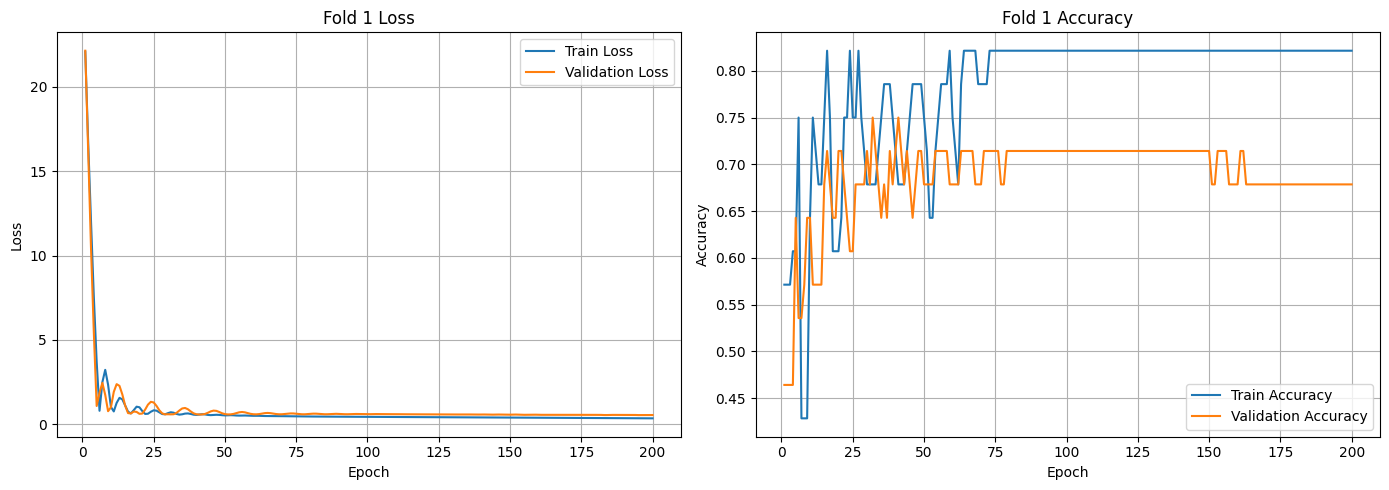

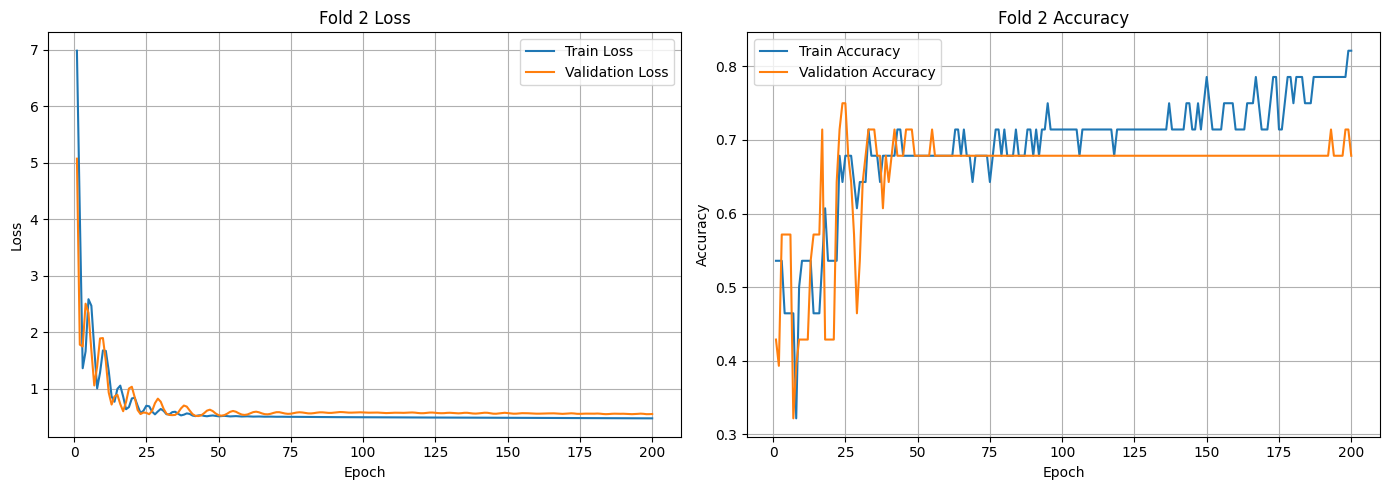

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from sklearn.model_selection import KFold
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Step 1: Add the label column
final_combined_df['label'] = final_combined_df['Participant'].apply(lambda x: 1 if 1 <= x <= 29 else 0)

# Step 2: Split into features and target
X = final_combined_df.drop(columns=['label', 'Participant']).values
y = final_combined_df['label'].values

# Step 3: Define the neural network architecture
class NeuralNet(nn.Module):
    def __init__(self, input_size):
        super(NeuralNet, self).__init__()
        self.fc1 = nn.Linear(input_size, 64)
        self.fc2 = nn.Linear(64, 32)
        self.fc3 = nn.Linear(32, 1)
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        x = torch.relu(self.fc1(x))
        x = torch.relu(self.fc2(x))
        x = self.sigmoid(self.fc3(x))
        return x

# Prepare KFold
kf = KFold(n_splits=2, shuffle=True, random_state=42)

num_epochs = 200
criterion = nn.BCELoss()

# Storage for all folds
fold_train_loss = {}
fold_val_loss = {}
fold_train_acc = {}
fold_val_acc = {}

fold_accuracy = {}
fold_precision = {}
fold_recall = {}
fold_f1 = {}

fold_index = 1

for train_index, test_index in kf.split(X):

    print(f"\n========== Fold {fold_index} ==========")

    # Split data
    X_train, X_test = X[train_index], X[test_index]
    y_train, y_test = y[train_index], y[test_index]

    # Convert tensors
    X_train_tensor = torch.tensor(X_train, dtype=torch.float32)
    y_train_tensor = torch.tensor(y_train, dtype=torch.float32).unsqueeze(1)
    X_test_tensor = torch.tensor(X_test, dtype=torch.float32)
    y_test_tensor = torch.tensor(y_test, dtype=torch.float32).unsqueeze(1)

    # Create model and optimizer
    input_size = X_train.shape[1]
    model = NeuralNet(input_size)
    optimizer = optim.Adam(model.parameters(), lr=0.001)

    # Store epoch-wise metrics
    train_losses = []
    val_losses = []
    train_accs = []
    val_accs = []

    # Training loop
    for epoch in range(num_epochs):
        model.train()
        optimizer.zero_grad()

        outputs = model(X_train_tensor)
        loss = criterion(outputs, y_train_tensor)
        loss.backward()
        optimizer.step()

        # Store training loss
        train_losses.append(loss.item())

        # Compute training accuracy
        train_pred = (outputs >= 0.5).float()
        train_acc = accuracy_score(y_train_tensor.numpy(), train_pred.numpy())
        train_accs.append(train_acc)

        # Validation step
        model.eval()
        with torch.no_grad():
            val_outputs = model(X_test_tensor)
            val_loss = criterion(val_outputs, y_test_tensor)
            val_pred = (val_outputs >= 0.5).float()
            val_acc = accuracy_score(y_test_tensor.numpy(), val_pred.numpy())

        val_losses.append(val_loss.item())
        val_accs.append(val_acc)

        if (epoch+1) % 10 == 0:
            print(f"Fold {fold_index}, Epoch {epoch+1}, Train Loss={loss.item():.4f}, Val Loss={val_loss.item():.4f}")

    # Save the history
    fold_train_loss[fold_index] = train_losses
    fold_val_loss[fold_index] = val_losses
    fold_train_acc[fold_index] = train_accs
    fold_val_acc[fold_index] = val_accs

    # Final evaluation per fold
    y_true_np = y_test_tensor.numpy()
    y_pred_np = val_pred.numpy()

    acc = accuracy_score(y_true_np, y_pred_np)
    prec = precision_score(y_true_np, y_pred_np)
    rec = recall_score(y_true_np, y_pred_np)
    f1 = f1_score(y_true_np, y_pred_np)

    fold_accuracy[fold_index] = acc
    fold_precision[fold_index] = prec
    fold_recall[fold_index] = rec
    fold_f1[fold_index] = f1

    print(f"Fold {fold_index} Accuracy:  {acc:.4f}")
    print(f"Fold {fold_index} Precision: {prec:.4f}")
    print(f"Fold {fold_index} Recall:    {rec:.4f}")
    print(f"Fold {fold_index} F1 Score:  {f1:.4f}")

    fold_index += 1

# Final output
print("\n========== Final Results ==========")
for fold in fold_accuracy.keys():
    print(f"\nFold {fold}:")
    print(f"  Accuracy:  {fold_accuracy[fold]:.4f}")
    print(f"  Precision: {fold_precision[fold]:.4f}")
    print(f"  Recall:    {fold_recall[fold]:.4f}")
    print(f"  F1 Score:  {fold_f1[fold]:.4f}")


import matplotlib.pyplot as plt

# Plot NN training curves for each fold
for fold in fold_train_loss.keys():

    train_loss = fold_train_loss[fold]
    val_loss = fold_val_loss[fold]
    train_acc = fold_train_acc[fold]
    val_acc = fold_val_acc[fold]

    epochs = range(1, len(train_loss) + 1)

    plt.figure(figsize=(14, 5))

    # === Left: Loss ===
    plt.subplot(1, 2, 1)
    plt.plot(epochs, train_loss, label="Train Loss")
    plt.plot(epochs, val_loss, label="Validation Loss")
    plt.title(f"Fold {fold} Loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.grid(True)
    plt.legend()

    # === Right: Accuracy ===
    plt.subplot(1, 2, 2)
    plt.plot(epochs, train_acc, label="Train Accuracy")
    plt.plot(epochs, val_acc, label="Validation Accuracy")
    plt.title(f"Fold {fold} Accuracy")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.grid(True)
    plt.legend()

    plt.tight_layout()
    plt.show()



### SVM

Accuracy: 0.5833
Precision: 0.6667
Recall: 0.3333
F1 Score: 0.4444
ROC AUC: 0.8333


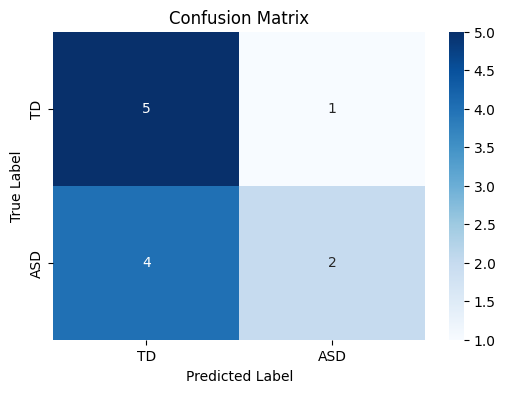

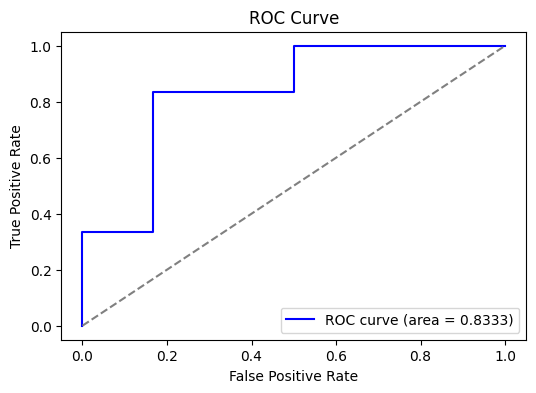

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import confusion_matrix, roc_auc_score, accuracy_score, precision_score, recall_score, f1_score, roc_curve
import matplotlib.pyplot as plt
import seaborn as sns

# Step 1: Add the label column
final_combined_df['label'] = final_combined_df['Participant'].apply(lambda x: 1 if 1 <= x <= 29 else 0)

# Step 2: Split into features and target
X = final_combined_df.drop(columns=['label', 'Participant']).values  # Convert to NumPy array
y = final_combined_df['label'].values  # Convert to NumPy array

# Step 3: Train-test split (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Step 4: Scale the features (important for SVM)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Step 5: Define and train the SVM classifier
svm_model = SVC(kernel='rbf', probability=True, random_state=42)
svm_model.fit(X_train_scaled, y_train)

# Step 6: Make predictions
y_pred_test = svm_model.predict(X_test_scaled)
y_proba_test = svm_model.predict_proba(X_test_scaled)[:, 1]  # Probabilities for ROC AUC

# Step 7: Calculate the evaluation metrics
conf_matrix = confusion_matrix(y_test, y_pred_test)
roc_auc = roc_auc_score(y_test, y_proba_test)
accuracy = accuracy_score(y_test, y_pred_test)
precision = precision_score(y_test, y_pred_test)
recall = recall_score(y_test, y_pred_test)
f1 = f1_score(y_test, y_pred_test)

# Step 8: Print the results
print(f"Accuracy: {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1 Score: {f1:.4f}")
print(f"ROC AUC: {roc_auc:.4f}")

# Step 9: Confusion Matrix plot
plt.figure(figsize=(6, 4))
sns.heatmap(conf_matrix, annot=True, fmt="d", cmap="Blues", xticklabels=['TD', 'ASD'], yticklabels=['TD', 'ASD'])
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix')
plt.show()

# Step 10: Plot ROC curve
fpr, tpr, _ = roc_curve(y_test, y_proba_test)
plt.figure(figsize=(6, 4))
plt.plot(fpr, tpr, color='blue', label=f'ROC curve (area = {roc_auc:.4f})')
plt.plot([0, 1], [0, 1], color='gray', linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend(loc='lower right')
plt.show()


#### SVM – 2-fold cross-validation

In [ ]:
from sklearn.model_selection import KFold
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import (
    confusion_matrix, roc_auc_score, accuracy_score,
    precision_score, recall_score, f1_score, roc_curve
)
import numpy as np

# Step 1: Add the label column
final_combined_df['label'] = final_combined_df['Participant'].apply(lambda x: 1 if 1 <= x <= 29 else 0)

# Step 2: Split into features and target
X = final_combined_df.drop(columns=['label', 'Participant']).values
y = final_combined_df['label'].values

# Prepare 2-fold cross validation
kf = KFold(n_splits=2, shuffle=True, random_state=42)

# Storage for all fold results
fold_accuracy = {}
fold_precision = {}
fold_recall = {}
fold_f1 = {}
fold_auc = {}

fold_index = 1

for train_index, test_index in kf.split(X):
    print(f"\n========== Fold {fold_index} ==========")

    # Split data
    X_train, X_test = X[train_index], X[test_index]
    y_train, y_test = y[train_index], y[test_index]

    # Standardize inside each fold
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)

    # Define and train SVM
    svm_model = SVC(kernel='rbf', probability=True, random_state=42)
    svm_model.fit(X_train_scaled, y_train)

    # Predictions
    y_pred = svm_model.predict(X_test_scaled)
    y_proba = svm_model.predict_proba(X_test_scaled)[:, 1]

    # Metrics
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    auc = roc_auc_score(y_test, y_proba)

    # Store results
    fold_accuracy[fold_index] = acc
    fold_precision[fold_index] = prec
    fold_recall[fold_index] = rec
    fold_f1[fold_index] = f1
    fold_auc[fold_index] = auc

    # Print results per fold
    print(f"Accuracy:  {acc:.4f}")
    print(f"Precision: {prec:.4f}")
    print(f"Recall:    {rec:.4f}")
    print(f"F1 Score:  {f1:.4f}")
    print(f"ROC AUC:   {auc:.4f}")

    fold_index += 1

# Final summary
print("\n========== Final 2-Fold Results ==========")
for f in fold_accuracy.keys():
    print(f"\nFold {f}:")
    print(f"  Accuracy:  {fold_accuracy[f]:.4f}")
    print(f"  Precision: {fold_precision[f]:.4f}")
    print(f"  Recall:    {fold_recall[f]:.4f}")
    print(f"  F1 Score:  {fold_f1[f]:.4f}")
    print(f"  ROC AUC:   {fold_auc[f]:.4f}")



========== Fold 1 ==========
Accuracy:  0.5714
Precision: 0.8000
Recall:    0.2667
F1 Score:  0.4000
ROC AUC:   0.8564

========== Fold 2 ==========
Accuracy:  0.7500
Precision: 0.6667
Recall:    0.8333
F1 Score:  0.7407
ROC AUC:   0.8229

========== Final 2-Fold Results ==========

Fold 1:
  Accuracy:  0.5714
  Precision: 0.8000
  Recall:    0.2667
  F1 Score:  0.4000
  ROC AUC:   0.8564

Fold 2:
  Accuracy:  0.7500
  Precision: 0.6667
  Recall:    0.8333
  F1 Score:  0.7407
  ROC AUC:   0.8229


### Decision Tree

Accuracy: 1.0000
Precision: 1.0000
Recall: 1.0000
F1 Score: 1.0000
ROC AUC: 1.0000


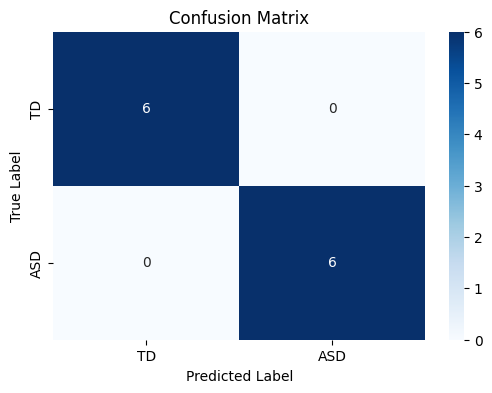

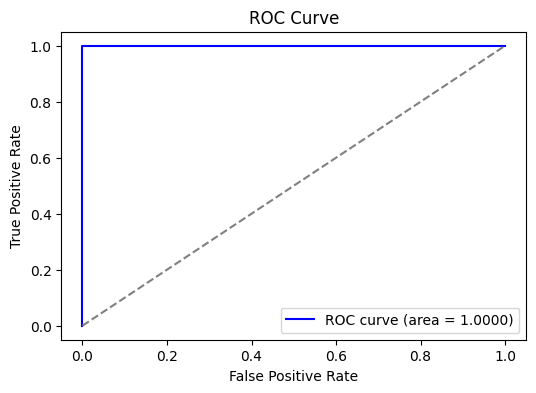

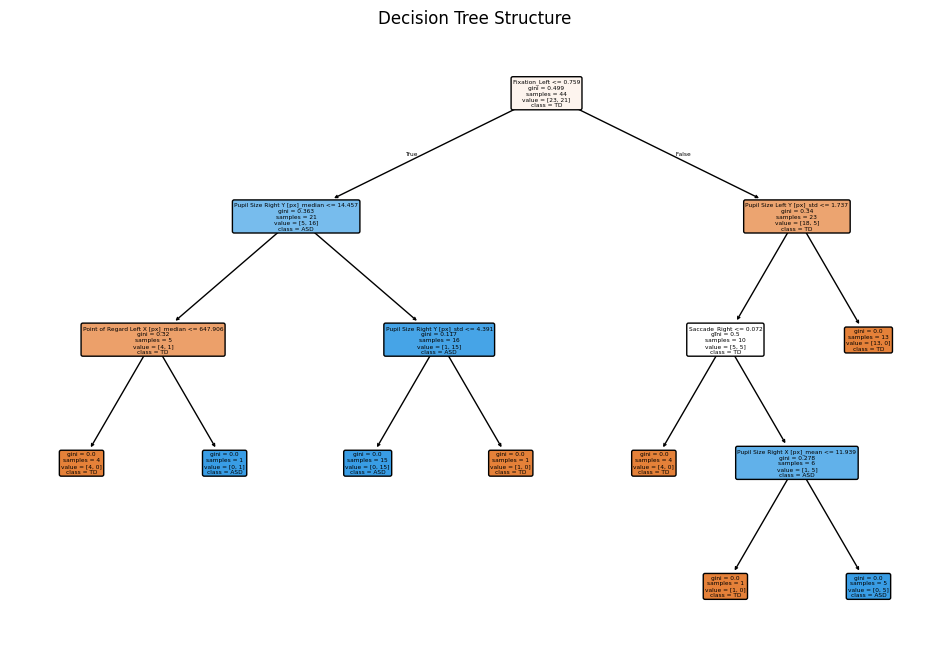

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import confusion_matrix, roc_auc_score, accuracy_score, precision_score, recall_score, f1_score, roc_curve
import matplotlib.pyplot as plt
import seaborn as sns

# Step 1: Add the label column
final_combined_df['label'] = final_combined_df['Participant'].apply(lambda x: 1 if 1 <= x <= 29 else 0)

# Step 2: Split into features and target
X = final_combined_df.drop(columns=['label', 'Participant']).values
y = final_combined_df['label'].values

# Step 3: Train-test split (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Step 4: Define and train the Decision Tree classifier
dt_model = DecisionTreeClassifier(random_state=42)
dt_model.fit(X_train, y_train)

# Step 5: Make predictions
y_pred_test = dt_model.predict(X_test)
y_proba_test = dt_model.predict_proba(X_test)[:, 1]  # Probabilities for ROC AUC

# Step 6: Calculate evaluation metrics
conf_matrix = confusion_matrix(y_test, y_pred_test)
roc_auc = roc_auc_score(y_test, y_proba_test)
accuracy = accuracy_score(y_test, y_pred_test)
precision = precision_score(y_test, y_pred_test)
recall = recall_score(y_test, y_pred_test)
f1 = f1_score(y_test, y_pred_test)

# Step 7: Print the results
print(f"Accuracy: {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1 Score: {f1:.4f}")
print(f"ROC AUC: {roc_auc:.4f}")

# Step 8: Confusion Matrix plot
plt.figure(figsize=(6, 4))
sns.heatmap(conf_matrix, annot=True, fmt="d", cmap="Blues", xticklabels=['TD', 'ASD'], yticklabels=['TD', 'ASD'])
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix')
plt.show()

# Step 9: Plot ROC curve
fpr, tpr, _ = roc_curve(y_test, y_proba_test)
plt.figure(figsize=(6, 4))
plt.plot(fpr, tpr, color='blue', label=f'ROC curve (area = {roc_auc:.4f})')
plt.plot([0, 1], [0, 1], color='gray', linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend(loc='lower right')
plt.show()

# Optional Step 10: Plot the Decision Tree structure
plt.figure(figsize=(12, 8))
plot_tree(dt_model, filled=True, feature_names=final_combined_df.drop(columns=['label', 'Participant']).columns, class_names=['TD', 'ASD'], rounded=True)
plt.title("Decision Tree Structure")
plt.show()


### Naive Bayes

Accuracy: 0.9167
Precision: 1.0000
Recall: 0.8333
F1 Score: 0.9091
ROC AUC: 0.9167


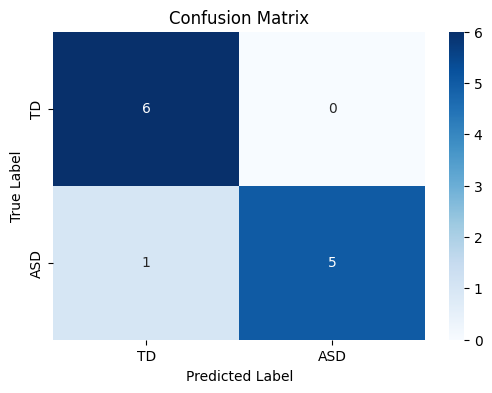

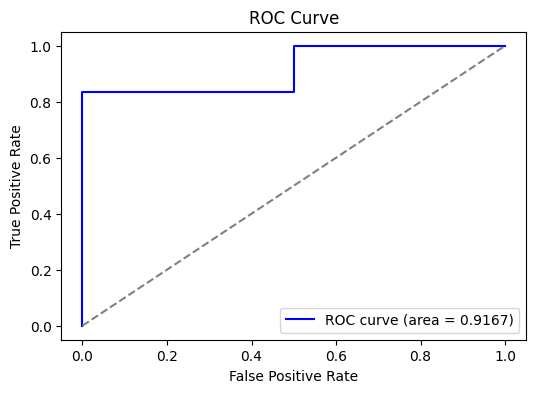

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import confusion_matrix, roc_auc_score, accuracy_score, precision_score, recall_score, f1_score, roc_curve
import matplotlib.pyplot as plt
import seaborn as sns

# Step 1: Add the label column
final_combined_df['label'] = final_combined_df['Participant'].apply(lambda x: 1 if 1 <= x <= 29 else 0)

# Step 2: Split into features and target
X = final_combined_df.drop(columns=['label', 'Participant']).values
y = final_combined_df['label'].values

# Step 3: Train-test split (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Step 4: Define and train the Naive Bayes classifier
nb_model = GaussianNB()
nb_model.fit(X_train, y_train)

# Step 5: Make predictions
y_pred_test = nb_model.predict(X_test)
y_proba_test = nb_model.predict_proba(X_test)[:, 1]  # Probabilities for ROC AUC

# Step 6: Calculate evaluation metrics
conf_matrix = confusion_matrix(y_test, y_pred_test)
roc_auc = roc_auc_score(y_test, y_proba_test)
accuracy = accuracy_score(y_test, y_pred_test)
precision = precision_score(y_test, y_pred_test)
recall = recall_score(y_test, y_pred_test)
f1 = f1_score(y_test, y_pred_test)

# Step 7: Print the results
print(f"Accuracy: {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1 Score: {f1:.4f}")
print(f"ROC AUC: {roc_auc:.4f}")

# Step 8: Confusion Matrix plot
plt.figure(figsize=(6, 4))
sns.heatmap(conf_matrix, annot=True, fmt="d", cmap="Blues", xticklabels=['TD', 'ASD'], yticklabels=['TD', 'ASD'])
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix')
plt.show()

# Step 9: Plot ROC curve
fpr, tpr, _ = roc_curve(y_test, y_proba_test)
plt.figure(figsize=(6, 4))
plt.plot(fpr, tpr, color='blue', label=f'ROC curve (area = {roc_auc:.4f})')
plt.plot([0, 1], [0, 1], color='gray', linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend(loc='lower right')
plt.show()


### KNN

Accuracy: 0.8333
Precision: 0.8333
Recall: 0.8333
F1 Score: 0.8333
ROC AUC: 0.9306


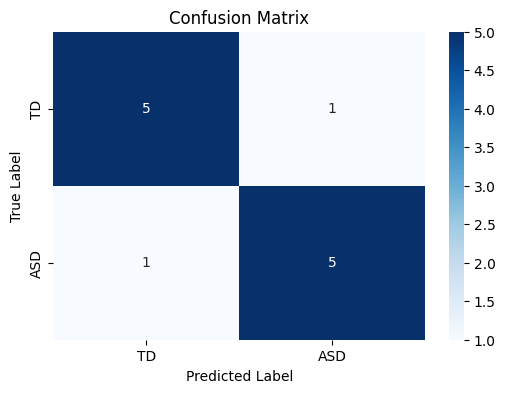

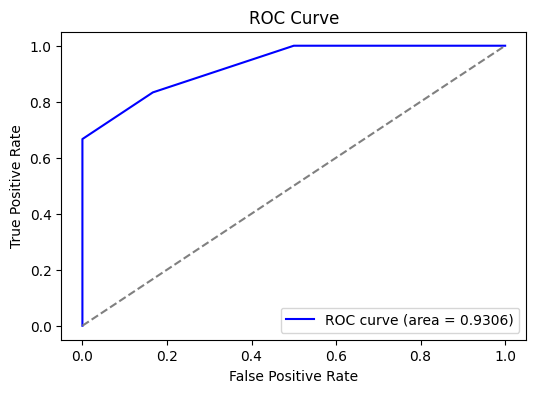

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import confusion_matrix, roc_auc_score, accuracy_score, precision_score, recall_score, f1_score, roc_curve
import matplotlib.pyplot as plt
import seaborn as sns

# Step 1: Add the label column
final_combined_df['label'] = final_combined_df['Participant'].apply(lambda x: 1 if 1 <= x <= 29 else 0)

# Step 2: Split into features and target
X = final_combined_df.drop(columns=['label', 'Participant']).values
y = final_combined_df['label'].values

# Step 3: Train-test split (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Step 4: Scale the features (important for kNN)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Step 5: Define and train the kNN classifier
knn_model = KNeighborsClassifier(n_neighbors=5)  # You can change k here
knn_model.fit(X_train_scaled, y_train)

# Step 6: Make predictions
y_pred_test = knn_model.predict(X_test_scaled)
y_proba_test = knn_model.predict_proba(X_test_scaled)[:, 1]  # Probabilities for ROC AUC

# Step 7: Calculate evaluation metrics
conf_matrix = confusion_matrix(y_test, y_pred_test)
roc_auc = roc_auc_score(y_test, y_proba_test)
accuracy = accuracy_score(y_test, y_pred_test)
precision = precision_score(y_test, y_pred_test)
recall = recall_score(y_test, y_pred_test)
f1 = f1_score(y_test, y_pred_test)

# Step 8: Print the results
print(f"Accuracy: {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1 Score: {f1:.4f}")
print(f"ROC AUC: {roc_auc:.4f}")

# Step 9: Confusion Matrix plot
plt.figure(figsize=(6, 4))
sns.heatmap(conf_matrix, annot=True, fmt="d", cmap="Blues", xticklabels=['TD', 'ASD'], yticklabels=['TD', 'ASD'])
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix')
plt.show()

# Step 10: Plot ROC curve
fpr, tpr, _ = roc_curve(y_test, y_proba_test)
plt.figure(figsize=(6, 4))
plt.plot(fpr, tpr, color='blue', label=f'ROC curve (area = {roc_auc:.4f})')
plt.plot([0, 1], [0, 1], color='gray', linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend(loc='lower right')
plt.show()


### Random Forest

Accuracy: 0.9167
Precision: 0.8571
Recall: 1.0000
F1 Score: 0.9231
ROC AUC: 0.9722


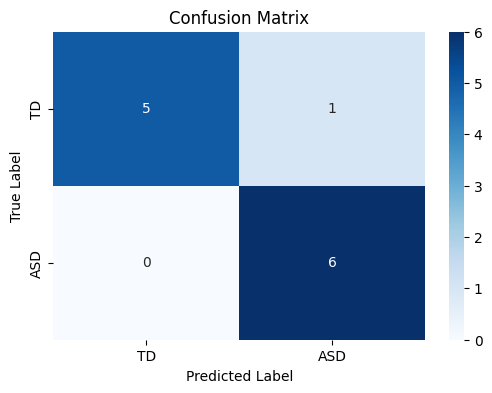

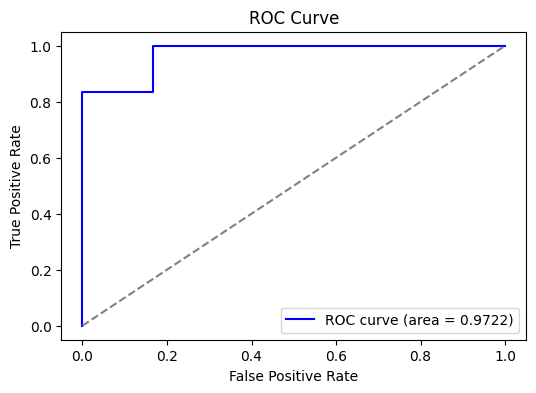

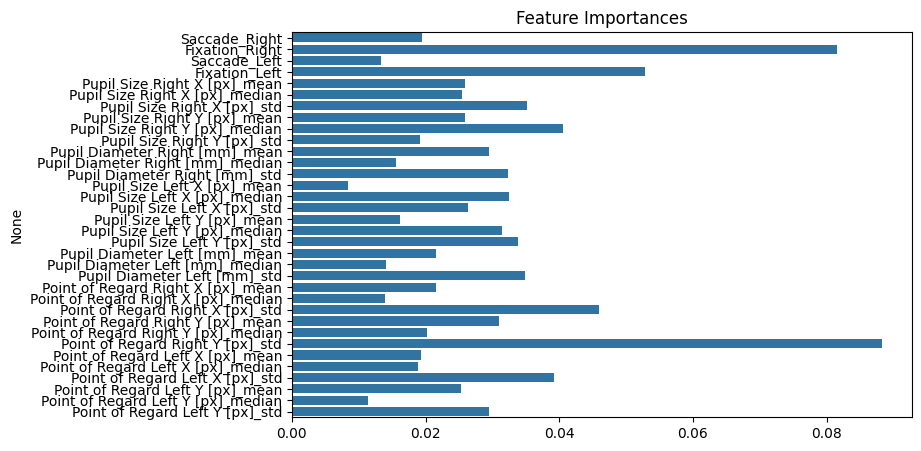

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, roc_auc_score, accuracy_score, precision_score, recall_score, f1_score, roc_curve
import matplotlib.pyplot as plt
import seaborn as sns

# Step 1: Add the label column
final_combined_df['label'] = final_combined_df['Participant'].apply(lambda x: 1 if 1 <= x <= 29 else 0)

# Step 2: Split into features and target
X = final_combined_df.drop(columns=['label', 'Participant']).values
y = final_combined_df['label'].values

# Step 3: Train-test split (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Step 4: Define and train the Random Forest classifier
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)  # n_estimators can be tuned
rf_model.fit(X_train, y_train)

# Step 5: Make predictions
y_pred_test = rf_model.predict(X_test)
y_proba_test = rf_model.predict_proba(X_test)[:, 1]  # Probabilities for ROC AUC

# Step 6: Calculate evaluation metrics
conf_matrix = confusion_matrix(y_test, y_pred_test)
roc_auc = roc_auc_score(y_test, y_proba_test)
accuracy = accuracy_score(y_test, y_pred_test)
precision = precision_score(y_test, y_pred_test)
recall = recall_score(y_test, y_pred_test)
f1 = f1_score(y_test, y_pred_test)

# Step 7: Print the results
print(f"Accuracy: {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1 Score: {f1:.4f}")
print(f"ROC AUC: {roc_auc:.4f}")

# Step 8: Confusion Matrix plot
plt.figure(figsize=(6, 4))
sns.heatmap(conf_matrix, annot=True, fmt="d", cmap="Blues", xticklabels=['TD', 'ASD'], yticklabels=['TD', 'ASD'])
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix')
plt.show()

# Step 9: Plot ROC curve
fpr, tpr, _ = roc_curve(y_test, y_proba_test)
plt.figure(figsize=(6, 4))
plt.plot(fpr, tpr, color='blue', label=f'ROC curve (area = {roc_auc:.4f})')
plt.plot([0, 1], [0, 1], color='gray', linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend(loc='lower right')
plt.show()

# Optional Step 10: Feature importance plot
plt.figure(figsize=(8, 5))
importances = rf_model.feature_importances_
feature_names = final_combined_df.drop(columns=['label', 'Participant']).columns
sns.barplot(x=importances, y=feature_names)
plt.title("Feature Importances")
plt.show()
